In [1]:

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, brier_score_loss, roc_auc_score, confusion_matrix
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
N_SPLITS = 5

# Reproducibility copy: resolve the dataset beside this notebook.
# The scientific analyses below remain unchanged.
DATA_FILE = "Disease with Weather.xlsx"
if not os.path.isfile(DATA_FILE):
    raise FileNotFoundError(
        "Dataset missing. Place 'Disease with Weather.xlsx' in the same folder "
        "as the notebook and start JupyterLab from that folder."
    )

print("Dataset:", DATA_FILE)


Dataset: Disease with Weather.xlsx


In [2]:

df_raw = pd.read_excel(DATA_FILE)

FEATURES = ["Temperature", "Humidity", "Visibility"]
TARGET = "Disease in number"

df = df_raw[FEATURES + [TARGET]].dropna().copy()
df[TARGET] = df[TARGET].astype(int)

print("Shape:", df.shape)
print("\nDisease counts:")
print(df[TARGET].value_counts().sort_index().rename(
    index={0:"Late Blight (0)", 1:"Early Blight (1)"}
))
print("\nMissing values:")
print(df.isna().sum())
df.head()


Shape: (4020, 4)

Disease counts:
Disease in number
Late Blight (0)     1954
Early Blight (1)    2066
Name: count, dtype: int64

Missing values:
Temperature          0
Humidity             0
Visibility           0
Disease in number    0
dtype: int64


,Temperature,Humidity,Visibility,Disease in number
0,18.7,77,11.0,1
1,23.4,64,8.9,0
2,20.1,72,10.0,1
3,25.6,61,9.6,0
4,19.5,78,12.5,1


In [3]:

def fit_thresholds(train_df, scheme="tertile"):
    if scheme == "tertile":
        qs = (1/3, 2/3)
    elif scheme == "q1q3":
        qs = (0.25, 0.75)
    else:
        raise ValueError("scheme must be 'tertile' or 'q1q3'")

    return {
        col: tuple(train_df[col].quantile(qs).to_numpy())
        for col in FEATURES
    }


def discretize(data_df, thresholds):
    out = pd.DataFrame(index=data_df.index)
    for col in FEATURES:
        lower, upper = thresholds[col]
        out[col] = np.where(
            data_df[col] <= lower, 0,
            np.where(data_df[col] <= upper, 1, 2)
        ).astype(int)
    return out


def metric_row(y_true, y_pred, p_early):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Late_Precision": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Late_Recall": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Late_F1": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "LogLoss": log_loss(y_true, np.clip(p_early, 1e-15, 1-1e-15), labels=[0,1]),
        "Brier": brier_score_loss(y_true, p_early),
        "AUC": roc_auc_score(y_true, p_early),
    }


In [4]:

def direct_bn_predict(train_disc, y_train, test_disc, estimator="bdeu", ess=5):
    train = train_disc.copy()
    train["D"] = np.asarray(y_train, dtype=int)
    counts = train.groupby(FEATURES + ["D"]).size()

    r = 2
    q = 3 ** len(FEATURES)

    if estimator == "mle":
        alpha = 0.0
    elif estimator == "k2":
        alpha = 1.0
    elif estimator == "bdeu":
        alpha = ess / (r * q)
    else:
        raise ValueError("Unknown estimator")

    majority_class = int(pd.Series(y_train).mode().iloc[0])

    predictions, p_early = [], []
    unseen = 0
    ties = 0

    for config in test_disc[FEATURES].itertuples(index=False, name=None):
        n_late = int(counts.get(tuple(config) + (0,), 0))
        n_early = int(counts.get(tuple(config) + (1,), 0))

        if n_late + n_early == 0:
            unseen += 1

        denominator = n_late + n_early + 2 * alpha

        if denominator == 0:
            p1 = 0.5
        else:
            p1 = (n_early + alpha) / denominator

        if p1 > 0.5:
            pred = 1
        elif p1 < 0.5:
            pred = 0
        else:
            ties += 1
            pred = majority_class

        predictions.append(pred)
        p_early.append(p1)

    return (
        np.asarray(predictions, dtype=int),
        np.asarray(p_early, dtype=float),
        {"unseen_test_cases": unseen, "ties": ties, "alpha": alpha}
    )


In [5]:

def naive_bn_predict(train_disc, y_train, test_disc, estimator="bdeu", ess=5):
    y_train = np.asarray(y_train, dtype=int)

    if estimator == "mle":
        alpha_d = 0.0
    elif estimator == "k2":
        alpha_d = 1.0
    elif estimator == "bdeu":
        alpha_d = ess / 2
    else:
        raise ValueError("Unknown estimator")

    disease_counts = np.bincount(y_train, minlength=2)
    disease_prior = (disease_counts + alpha_d) / (len(y_train) + 2 * alpha_d)

    if estimator == "mle":
        alpha_x = 0.0
    elif estimator == "k2":
        alpha_x = 1.0
    else:
        alpha_x = ess / (3 * 2)

    cpts = {}

    for col in FEATURES:
        table = np.zeros((2, 3), dtype=int)
        x = train_disc[col].to_numpy()

        for d in (0, 1):
            for state in (0, 1, 2):
                table[d, state] = np.sum((y_train == d) & (x == state))

        denom = table.sum(axis=1, keepdims=True) + 3 * alpha_x
        probs = (table + alpha_x) / denom
        cpts[col] = probs

    predictions, p_early = [], []

    for config in test_disc[FEATURES].itertuples(index=False, name=None):
        log_joint = []

        for d in (0, 1):
            lp = np.log(max(disease_prior[d], 1e-300))
            for col, state in zip(FEATURES, config):
                lp += np.log(max(cpts[col][d, state], 1e-300))
            log_joint.append(lp)

        m = max(log_joint)
        probs = np.exp(np.asarray(log_joint) - m)
        probs /= probs.sum()

        p_early.append(probs[1])
        predictions.append(int(np.argmax(probs)))

    return np.asarray(predictions), np.asarray(p_early)


In [6]:

def run_cv(model="direct", scheme="tertile", estimator="bdeu", ess=5):
    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    fold_rows = []
    all_true, all_pred, all_prob = [], [], []
    thresholds_by_fold = []
    diagnostics = []

    X = df[FEATURES]
    y = df[TARGET]

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
        train_df = df.iloc[train_idx].copy()
        test_df = df.iloc[test_idx].copy()

        thresholds = fit_thresholds(train_df, scheme=scheme)
        train_disc = discretize(train_df, thresholds)
        test_disc = discretize(test_df, thresholds)

        y_train = train_df[TARGET].to_numpy()
        y_test = test_df[TARGET].to_numpy()

        if model == "direct":
            pred, p1, diag = direct_bn_predict(
                train_disc, y_train, test_disc,
                estimator=estimator, ess=ess
            )
        elif model == "naive":
            pred, p1 = naive_bn_predict(
                train_disc, y_train, test_disc,
                estimator=estimator, ess=ess
            )
            diag = {}
        else:
            raise ValueError("model must be 'direct' or 'naive'")

        row = {"Fold": fold}
        row.update(metric_row(y_test, pred, p1))
        fold_rows.append(row)

        thresholds_by_fold.append({
            "Fold": fold,
            **{f"{col}_low": thresholds[col][0] for col in FEATURES},
            **{f"{col}_high": thresholds[col][1] for col in FEATURES},
        })

        diagnostics.append({"Fold": fold, **diag})

        all_true.extend(y_test.tolist())
        all_pred.extend(pred.tolist())
        all_prob.extend(p1.tolist())

    return {
        "folds": pd.DataFrame(fold_rows),
        "thresholds": pd.DataFrame(thresholds_by_fold),
        "diagnostics": pd.DataFrame(diagnostics),
        "confusion_matrix": confusion_matrix(all_true, all_pred, labels=[0,1]),
        "y_true": np.asarray(all_true),
        "y_pred": np.asarray(all_pred),
        "p_early": np.asarray(all_prob),
    }


def summarize_folds(fold_df):
    metrics = [c for c in fold_df.columns if c != "Fold"]
    return pd.DataFrame({
        "Mean": fold_df[metrics].mean(),
        "SD": fold_df[metrics].std(ddof=1)
    })


In [7]:

exp1_direct = run_cv(model="direct", scheme="tertile", estimator="bdeu", ess=5)
exp1_naive = run_cv(model="naive", scheme="tertile", estimator="bdeu", ess=5)

structure_summary = pd.DataFrame({
    "Diagnostic BN": summarize_folds(exp1_direct["folds"])["Mean"],
    "Naive BN": summarize_folds(exp1_naive["folds"])["Mean"],
}).T

display(structure_summary)
display(exp1_direct["folds"])
display(exp1_naive["folds"])


,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,LogLoss,Brier,AUC
Diagnostic BN,0.912438,0.911545,0.977260,0.839325,0.902758,0.208377,0.060557,0.964738
Naive BN,0.913184,0.912303,0.977901,0.840348,0.903615,0.269580,0.060471,0.965965


,Fold,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,LogLoss,Brier,AUC
0,1,0.936567,0.936124,0.988473,0.879487,0.930801,0.153206,0.045679,0.982160
1,2,0.929104,0.928609,0.982659,0.869565,0.922659,0.178546,0.050335,0.973517
2,3,0.893035,0.891488,0.981073,0.795396,0.878531,0.232681,0.068317,0.959891
3,4,0.891791,0.890509,0.966258,0.805627,0.878661,0.257041,0.075057,0.948468
4,5,0.911692,0.910997,0.967836,0.846547,0.903138,0.220413,0.063399,0.959655


,Fold,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,LogLoss,Brier,AUC
0,1,0.936567,0.936124,0.988473,0.879487,0.930801,0.149657,0.045332,0.982172
1,2,0.930348,0.929876,0.982709,0.872123,0.924119,0.227695,0.050274,0.973976
2,3,0.895522,0.894011,0.984227,0.797954,0.881356,0.308829,0.067655,0.961076
3,4,0.891791,0.890509,0.966258,0.805627,0.878661,0.345750,0.075102,0.952301
4,5,0.911692,0.910997,0.967836,0.846547,0.903138,0.315968,0.063991,0.960299


In [8]:

settings = [
    ("MLE", "mle", 5),
    ("K2", "k2", 5),
    ("BDeu ESS=1", "bdeu", 1),
    ("BDeu ESS=5", "bdeu", 5),
    ("BDeu ESS=10", "bdeu", 10),
    ("BDeu ESS=20", "bdeu", 20),
]

exp2_results = {}
rows = []

for label, estimator, ess in settings:
    result = run_cv(
        model="direct",
        scheme="tertile",
        estimator=estimator,
        ess=ess
    )
    exp2_results[label] = result
    means = result["folds"].drop(columns="Fold").mean()
    sds = result["folds"].drop(columns="Fold").std(ddof=1)

    row = {"Estimator": label}
    for metric in means.index:
        row[metric] = means[metric]
        row[f"{metric}_SD"] = sds[metric]
    rows.append(row)

exp2_summary = pd.DataFrame(rows)
display(exp2_summary[[
    "Estimator", "Accuracy", "Macro_F1", "LogLoss", "Brier", "AUC"
]])


,Estimator,Accuracy,Macro_F1,LogLoss,Brier,AUC
0,MLE,0.912438,0.911545,0.237505,0.060594,0.964497
1,K2,0.912438,0.911545,0.207142,0.060568,0.965967
2,BDeu ESS=1,0.912438,0.911545,0.209907,0.060585,0.964577
3,BDeu ESS=5,0.912438,0.911545,0.208377,0.060557,0.964738
4,BDeu ESS=10,0.912438,0.911545,0.207781,0.060537,0.964763
5,BDeu ESS=20,0.912438,0.911545,0.207293,0.060523,0.965024


In [9]:

mle_pred = exp2_results["MLE"]["y_pred"]
mle_prob = exp2_results["MLE"]["p_early"]

comparison = []
for label, result in exp2_results.items():
    comparison.append({
        "Estimator": label,
        "Predictions_changed_vs_MLE": int(np.sum(result["y_pred"] != mle_pred)),
        "Mean_abs_probability_change_vs_MLE": float(
            np.mean(np.abs(result["p_early"] - mle_prob))
        )
    })

display(pd.DataFrame(comparison))


,Estimator,Predictions_changed_vs_MLE,Mean_abs_probability_change_vs_MLE
0,MLE,0,0.000000
1,K2,0,0.004423
2,BDeu ESS=1,0,0.000094
3,BDeu ESS=5,0,0.000460
4,BDeu ESS=10,0,0.000902
5,BDeu ESS=20,0,0.001749


In [10]:

final_bn = run_cv(
    model="direct",
    scheme="tertile",
    estimator="bdeu",
    ess=5
)

print("Fold-wise results")
display(final_bn["folds"])

print("\nMean ± SD")
display(summarize_folds(final_bn["folds"]))

print("\nFold-specific thresholds")
display(final_bn["thresholds"])

print("\nDiagnostics")
display(final_bn["diagnostics"])

print("\nPooled confusion matrix [rows=actual Late/Early, cols=predicted Late/Early]")
print(final_bn["confusion_matrix"])


Fold-wise results


,Fold,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,LogLoss,Brier,AUC
0,1,0.936567,0.936124,0.988473,0.879487,0.930801,0.153206,0.045679,0.982160
1,2,0.929104,0.928609,0.982659,0.869565,0.922659,0.178546,0.050335,0.973517
2,3,0.893035,0.891488,0.981073,0.795396,0.878531,0.232681,0.068317,0.959891
3,4,0.891791,0.890509,0.966258,0.805627,0.878661,0.257041,0.075057,0.948468
4,5,0.911692,0.910997,0.967836,0.846547,0.903138,0.220413,0.063399,0.959655



Mean ± SD


,Mean,SD
Accuracy,0.912438,0.020392
Macro_F1,0.911545,0.020859
Late_Precision,0.977260,0.009737
Late_Recall,0.839325,0.037566
Late_F1,0.902758,0.024239
LogLoss,0.208377,0.041945
Brier,0.060557,0.012292
AUC,0.964738,0.013178



Fold-specific thresholds


,Fold,Temperature_low,Humidity_low,Visibility_low,Temperature_high,Humidity_high,Visibility_high
0,1,21.8,63.0,9.300000,25.1,72.0,10.8
1,2,21.8,63.0,9.300000,25.1,72.0,10.7
2,3,21.8,63.0,9.200000,25.2,72.0,10.7
3,4,21.8,63.0,9.266667,25.1,72.0,10.8
4,5,21.8,63.0,9.300000,25.1,72.0,10.8



Diagnostics


,Fold,unseen_test_cases,ties,alpha
0,1,0,0,0.092593
1,2,1,1,0.092593
2,3,2,2,0.092593
3,4,0,0,0.092593
4,5,0,0,0.092593



Pooled confusion matrix [rows=actual Late/Early, cols=predicted Late/Early]
[[1640  314]
 [  38 2028]]


In [11]:

cm = final_bn["confusion_matrix"]
tn_late, fn_late = cm[0,0], cm[0,1]
fp_late, tp_early = cm[1,0], cm[1,1]

late_sensitivity = tn_late / cm[0].sum()
late_specificity = tp_early / cm[1].sum()
late_precision = tn_late / (tn_late + fp_late)

print("Late Blight sensitivity:", late_sensitivity)
print("Late Blight specificity:", late_specificity)
print("Late Blight precision:", late_precision)


Late Blight sensitivity: 0.8393039918116684
Late Blight specificity: 0.9816069699903195
Late Blight precision: 0.9773539928486293


In [12]:

tertile = run_cv(
    model="direct",
    scheme="tertile",
    estimator="bdeu",
    ess=5
)

q1q3 = run_cv(
    model="direct",
    scheme="q1q3",
    estimator="bdeu",
    ess=5
)

disc_summary = pd.DataFrame({
    "Tertiles": summarize_folds(tertile["folds"])["Mean"],
    "Q1/Q3": summarize_folds(q1q3["folds"])["Mean"],
}).T

display(disc_summary)

print("\nTertile confusion matrix")
print(tertile["confusion_matrix"])

print("\nQ1/Q3 confusion matrix")
print(q1q3["confusion_matrix"])


,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,LogLoss,Brier,AUC
Tertiles,0.912438,0.911545,0.97726,0.839325,0.902758,0.208377,0.060557,0.964738
Q1/Q3,0.847015,0.842429,0.97894,0.700117,0.815712,0.286970,0.091487,0.931251



Tertile confusion matrix
[[1640  314]
 [  38 2028]]

Q1/Q3 confusion matrix
[[1368  586]
 [  29 2037]]


In [13]:

# ============================================================
# EXPERIMENT H1
# Gaussian fuzzy memberships and environmental compatibility
# ============================================================

from itertools import product

LINGUISTIC_STATES = ("Low", "Moderate", "High")
CONFIGURATIONS = list(product(range(3), repeat=len(FEATURES)))

assert len(CONFIGURATIONS) == 27


def fit_gaussian_mfs(train_df):
    """
    Fit Gaussian MF parameters using training data only.

    Linguistic groups are defined by training-fold tertiles.
    Each group's mean and standard deviation determine its
    Gaussian membership function.
    """
    thresholds = fit_thresholds(train_df, scheme="tertile")
    discrete = discretize(train_df, thresholds)

    parameters = {}

    for feature in FEATURES:
        parameters[feature] = {}

        for state in range(3):
            values = train_df.loc[
                discrete[feature] == state, feature
            ].to_numpy(dtype=float)

            if len(values) == 0:
                raise ValueError(
                    f"Empty training group: {feature}, state {state}"
                )

            centre = float(np.mean(values))
            sigma = float(np.std(values, ddof=0))

            # Prevent division by zero for constant-valued groups.
            sigma = max(sigma, 1e-6)

            parameters[feature][state] = (centre, sigma)

    return parameters


def gaussian_membership(x, centre, sigma):
    """Gaussian fuzzy membership in [0, 1]."""
    return np.exp(-0.5 * ((np.asarray(x) - centre) / sigma) ** 2)


def fuzzy_configuration_weights(data_df, mf_parameters):
    """
    Compute w_j(x) for all 27 environmental configurations.

    Returns an array of shape (n_observations, 27).
    These weights are fuzzy compatibility degrees,
    NOT probabilities.
    """
    memberships = {}

    for feature in FEATURES:
        x = data_df[feature].to_numpy(dtype=float)

        memberships[feature] = np.column_stack([
            gaussian_membership(
                x,
                *mf_parameters[feature][state]
            )
            for state in range(3)
        ])

    weights = np.column_stack([
        np.prod(
            [
                memberships[feature][:, state]
                for feature, state in zip(FEATURES, config)
            ],
            axis=0
        )
        for config in CONFIGURATIONS
    ])

    return weights


# ------------------------------------------------------------
# Validation using the first training fold
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    skf.split(df[FEATURES], df[TARGET])
)

train_fold = df.iloc[train_idx]
test_fold = df.iloc[test_idx]

mf_parameters = fit_gaussian_mfs(train_fold)

# Compute fuzzy compatibility for held-out observations.
W = fuzzy_configuration_weights(test_fold, mf_parameters)

# Mathematical checks
assert W.shape == (len(test_fold), 27)
assert np.all(np.isfinite(W))
assert np.all((W >= 0) & (W <= 1))

print("EXPERIMENT H1: FUZZY COMPATIBILITY")
print("-" * 48)
print("Training observations:", len(train_fold))
print("Test observations:", len(test_fold))
print("Environmental configurations:", len(CONFIGURATIONS))
print("Compatibility matrix shape:", W.shape)

print("\nGaussian membership parameters:")
rows = []

for feature in FEATURES:
    for state, (centre, sigma) in mf_parameters[feature].items():
        rows.append({
            "Feature": feature,
            "State": LINGUISTIC_STATES[state],
            "Centre": centre,
            "Sigma": sigma
        })

display(pd.DataFrame(rows).round(4))

print("\nFirst five observations:")
print("Sum of fuzzy configuration weights:",
      np.round(W[:5].sum(axis=1), 4))

print("\nCompatibility range:",
      round(float(W.min()), 6),
      "to",
      round(float(W.max()), 6))

print("\nAll mathematical checks passed.")


EXPERIMENT H1: FUZZY COMPATIBILITY
------------------------------------------------
Training observations: 3216
Test observations: 804
Environmental configurations: 27
Compatibility matrix shape: (804, 27)

Gaussian membership parameters:


,Feature,State,Centre,Sigma
0,Temperature,Low,20.4014,0.8583
1,Temperature,Moderate,23.4518,1.0235
2,Temperature,High,27.0179,1.1471
3,Humidity,Low,59.4457,2.6441
4,Humidity,Moderate,68.2041,2.7368
5,Humidity,High,75.1509,1.6547
6,Visibility,Low,8.8148,0.3267
7,Visibility,Moderate,10.0141,0.4226
8,Visibility,High,11.6919,0.4565



First five observations:
Sum of fuzzy configuration weights: [0.6785 0.598  0.6915 0.4377 0.1132]

Compatibility range: 0.0 to 0.968302

All mathematical checks passed.


In [14]:

# ============================================================
# EXPERIMENT H2
# Fuzzy-Bayesian evidence integration (first fold)
# ============================================================

import numpy as np
import pandas as pd

# Configuration: 3 states for each of T, H and V
N_STATES = 3
N_CLASSES = 2
ESS = 5.0

# BDeu prior for each disease-class / parent-configuration cell
ALPHA = ESS / (N_CLASSES * len(CONFIGURATIONS))


def estimate_bn_components(train_data, thresholds):
    """
    Estimate:
      1. P(J=j): environmental configuration probabilities
      2. P(Y=y | J=j): Bayesian conditional probabilities

    All estimates use training data only.
    """
    discrete_train = discretize(train_data, thresholds)

    # Match rows to the 27 configurations in Cell 12.
    state_matrix = discrete_train[FEATURES].to_numpy(dtype=int)

    config_lookup = {
        config: index
        for index, config in enumerate(CONFIGURATIONS)
    }

    config_indices = np.array([
        config_lookup[tuple(row)]
        for row in state_matrix
    ])

    # Keep the actual disease labels rather than assuming their
    # numerical encoding or ordering.
    classes = np.sort(train_data[TARGET].unique())

    if len(classes) != N_CLASSES:
        raise ValueError("Expected exactly two disease classes.")

    class_lookup = {
        label: index for index, label in enumerate(classes)
    }

    class_indices = np.array([
        class_lookup[label]
        for label in train_data[TARGET].to_numpy()
    ])

    # Count observations in each configuration and class.
    counts = np.zeros(
        (len(CONFIGURATIONS), N_CLASSES),
        dtype=float
    )

    np.add.at(counts, (config_indices, class_indices), 1)

    config_counts = counts.sum(axis=1)

    # Empirical configuration prior.
    p_j = config_counts / config_counts.sum()

    # BDeu-smoothed conditional probability table.
    cpt = (counts + ALPHA) / (
        config_counts[:, None] + N_CLASSES * ALPHA
    )

    return p_j, cpt, classes, counts


def hybrid_inference(W, p_j, cpt):
    """
    Convert fuzzy compatibility into normalized configuration
    weights, then marginalize over Bayesian disease CPTs.
    """
    weighted_mass = W * p_j[None, :]

    denominator = weighted_mass.sum(axis=1)

    if np.any(denominator <= 0):
        raise ValueError(
            "Zero fuzzy-evidence normalizer encountered."
        )

    # q_j(x): normalized configuration weights
    Q = weighted_mass / denominator[:, None]

    # P_H(Y | fuzzy evidence)
    posterior = Q @ cpt

    return Q, posterior, denominator


# ------------------------------------------------------------
# Fit Bayesian components using first training fold
# ------------------------------------------------------------

thresholds_h2 = fit_thresholds(
    train_fold,
    scheme="tertile"
)

p_j, cpt, classes, counts = estimate_bn_components(
    train_fold,
    thresholds_h2
)

# W was computed from the held-out observations in Cell 12.
Q, hybrid_posterior, evidence_mass = hybrid_inference(
    W, p_j, cpt
)


# ------------------------------------------------------------
# Mathematical validation
# ------------------------------------------------------------

assert p_j.shape == (27,)
assert cpt.shape == (27, 2)
assert Q.shape == (len(test_fold), 27)
assert hybrid_posterior.shape == (len(test_fold), 2)

assert np.all(np.isfinite(Q))
assert np.all(np.isfinite(hybrid_posterior))

assert np.all(p_j >= 0)
assert np.isclose(p_j.sum(), 1.0)

assert np.allclose(cpt.sum(axis=1), 1.0)
assert np.allclose(Q.sum(axis=1), 1.0)
assert np.allclose(hybrid_posterior.sum(axis=1), 1.0)

assert np.all((Q >= 0) & (Q <= 1))
assert np.all(
    (hybrid_posterior >= 0) &
    (hybrid_posterior <= 1)
)

# Crisp-evidence recovery:
# If exactly one configuration has compatibility 1,
# the hybrid posterior must reproduce that configuration's CPT.
j_star = int(np.argmax(p_j))

W_crisp = np.zeros((1, len(CONFIGURATIONS)))
W_crisp[0, j_star] = 1.0

_, crisp_posterior, _ = hybrid_inference(
    W_crisp, p_j, cpt
)

assert np.allclose(
    crisp_posterior[0],
    cpt[j_star]
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("EXPERIMENT H2: FUZZY-BAYESIAN INTEGRATION")
print("-" * 55)

print("Training observations:", len(train_fold))
print("Held-out observations:", len(test_fold))
print("Environmental configurations:", len(CONFIGURATIONS))
print("Disease classes:", classes)
print("BDeu ESS:", ESS)
print("BDeu alpha per CPT cell:", round(ALPHA, 6))

print("\nConfiguration prior P(J):")
print("Sum:", round(float(p_j.sum()), 8))
print("Minimum:", round(float(p_j.min()), 8))
print("Maximum:", round(float(p_j.max()), 8))
print("Configurations with zero training observations:",
      int(np.sum(counts.sum(axis=1) == 0)))

print("\nEvidence normalization:")
print("Minimum denominator:",
      round(float(evidence_mass.min()), 10))
print("Maximum denominator:",
      round(float(evidence_mass.max()), 10))

print("\nFirst five hybrid posterior distributions:")

posterior_table = pd.DataFrame(
    hybrid_posterior[:5],
    columns=[
        f"P({label} | fuzzy evidence)"
        for label in classes
    ]
)

display(posterior_table.round(6))

print("\nCrisp-evidence recovery test:")
print("Selected configuration:", CONFIGURATIONS[j_star])
print("BN CPT:", np.round(cpt[j_star], 6))
print("Recovered posterior:",
      np.round(crisp_posterior[0], 6))

print("\nAll mathematical checks passed.")


EXPERIMENT H2: FUZZY-BAYESIAN INTEGRATION
-------------------------------------------------------
Training observations: 3216
Held-out observations: 804
Environmental configurations: 27
Disease classes: [0 1]
BDeu ESS: 5.0
BDeu alpha per CPT cell: 0.092593

Configuration prior P(J):
Sum: 1.0
Minimum: 0.0
Maximum: 0.26554726
Configurations with zero training observations: 7

Evidence normalization:
Minimum denominator: 0.0
Maximum denominator: 0.2570852568

First five hybrid posterior distributions:


,P(0 | fuzzy evidence),P(1 | fuzzy evidence)
0,0.008533,0.991467
1,0.663536,0.336464
2,0.362554,0.637446
3,0.015808,0.984192
4,0.978827,0.021173



Crisp-evidence recovery test:
Selected configuration: (2, 0, 0)
BN CPT: [0.978819 0.021181]
Recovered posterior: [0.978819 0.021181]

All mathematical checks passed.


In [15]:

# ============================================================
# H2 DIAGNOSTIC: Evidence normalization and sparse states
# ============================================================

print("H2 DIAGNOSTIC")
print("-" * 50)

print("Minimum evidence denominator (scientific notation):",
      f"{evidence_mass.min():.12e}")

print("Maximum evidence denominator:",
      f"{evidence_mass.max():.12e}")

print("Exactly zero denominators:",
      np.sum(evidence_mass == 0))

print("Denominators below 1e-10:",
      np.sum(evidence_mass < 1e-10))

print("Denominators below 1e-6:",
      np.sum(evidence_mass < 1e-6))

print("\nEmpty environmental configurations:")

empty_indices = np.where(counts.sum(axis=1) == 0)[0]

for j in empty_indices:
    print(
        "Configuration:",
        CONFIGURATIONS[j],
        "| P(J):",
        p_j[j],
        "| CPT:",
        np.round(cpt[j], 6)
    )

print("\nPosterior normalization:")
print("Maximum deviation from 1:",
      np.max(np.abs(hybrid_posterior.sum(axis=1) - 1)))

print("\nCrisp-evidence recovery:")
print("BN CPT:", np.round(cpt[j_star], 8))
print("Recovered:", np.round(crisp_posterior[0], 8))
print("Difference:",
      np.max(np.abs(cpt[j_star] - crisp_posterior[0])))


H2 DIAGNOSTIC
--------------------------------------------------
Minimum evidence denominator (scientific notation): 9.621861311337e-13
Maximum evidence denominator: 2.570852568210e-01
Exactly zero denominators: 0
Denominators below 1e-10: 1
Denominators below 1e-6: 3

Empty environmental configurations:
Configuration: (0, 0, 0) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (0, 0, 1) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (1, 2, 0) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (2, 1, 2) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (2, 2, 0) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (2, 2, 1) | P(J): 0.0 | CPT: [0.5 0.5]
Configuration: (2, 2, 2) | P(J): 0.0 | CPT: [0.5 0.5]

Posterior normalization:
Maximum deviation from 1: 4.440892098500626e-16

Crisp-evidence recovery:
BN CPT: [0.97881889 0.02118111]
Recovered: [0.97881889 0.02118111]
Difference: 0.0


In [16]:

# ============================================================
# EXPERIMENT H3
# Stratified 5-fold evaluation of H-v1 Fuzzy-Bayesian Hybrid
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

fold_results = []
all_true = []
all_pred = []
all_prob_late = []

skf_h3 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for fold, (train_idx, test_idx) in enumerate(
    skf_h3.split(df[FEATURES], df[TARGET]), start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    # 1. Fit Gaussian membership functions
    # using training data only.
    mf_params = fit_gaussian_mfs(train_data)

    # 2. Compute held-out fuzzy compatibility.
    W_fold = fuzzy_configuration_weights(
        test_data, mf_params
    )

    # 3. Fit training-fold tertile thresholds.
    thresholds = fit_thresholds(
        train_data, scheme="tertile"
    )

    # 4. Estimate P(J) and P(Y|J) from training data.
    p_j_fold, cpt_fold, classes_fold, counts_fold = (
        estimate_bn_components(train_data, thresholds)
    )

    # 5. Hybrid inference.
    Q_fold, posterior_fold, denominator_fold = (
        hybrid_inference(W_fold, p_j_fold, cpt_fold)
    )

    # Mathematical validation.
    assert np.all(np.isfinite(posterior_fold))
    assert np.allclose(
        posterior_fold.sum(axis=1), 1.0
    )

    # Dataset coding: 0 = Late, 1 = Early.
    late_index = np.where(classes_fold == 0)[0][0]

    y_true = test_data[TARGET].to_numpy()
    y_pred = classes_fold[
        np.argmax(posterior_fold, axis=1)
    ]

    p_late = posterior_fold[:, late_index]
    y_late = (y_true == 0).astype(int)
    pred_late = (y_pred == 0).astype(int)

    fold_result = {
        "Fold": fold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Late_Precision": precision_score(
            y_late, pred_late, zero_division=0
        ),
        "Late_Recall": recall_score(
            y_late, pred_late, zero_division=0
        ),
        "Late_F1": f1_score(
            y_late, pred_late, zero_division=0
        ),
        "AUC": roc_auc_score(y_late, p_late),
        "Log_Loss": log_loss(
            y_late,
            p_late,
            labels=[0, 1]
        ),
        "Brier": brier_score_loss(y_late, p_late),
        "Empty_Configurations": int(
            np.sum(counts_fold.sum(axis=1) == 0)
        ),
        "Min_Denominator": float(
            denominator_fold.min()
        ),
        "Denom_Below_1e-10": int(
            np.sum(denominator_fold < 1e-10)
        ),
        "Denom_Below_1e-6": int(
            np.sum(denominator_fold < 1e-6)
        )
    }

    fold_results.append(fold_result)

    all_true.extend(y_true)
    all_pred.extend(y_pred)
    all_prob_late.extend(p_late)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

h3_results = pd.DataFrame(fold_results)

metric_columns = [
    "Accuracy",
    "Macro_F1",
    "Late_Precision",
    "Late_Recall",
    "Late_F1",
    "AUC",
    "Log_Loss",
    "Brier"
]

print("EXPERIMENT H3: FIVE-FOLD HYBRID EVALUATION")
print("=" * 60)

print("\nFold-wise results:")
display(h3_results.round(6))

print("\nMean ± standard deviation:")

summary = pd.DataFrame({
    "Mean": h3_results[metric_columns].mean(),
    "SD": h3_results[metric_columns].std(ddof=1)
})

display(summary.round(4))

print("\nEvidence-support diagnostics:")

display(
    h3_results[
        [
            "Fold",
            "Empty_Configurations",
            "Min_Denominator",
            "Denom_Below_1e-10",
            "Denom_Below_1e-6"
        ]
    ]
)

print("\nPooled confusion matrix:")
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Late", "Actual Early"],
        columns=["Predicted Late", "Predicted Early"]
    )
)

print("\nExperiment H3 completed.")


EXPERIMENT H3: FIVE-FOLD HYBRID EVALUATION

Fold-wise results:


,Fold,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,AUC,Log_Loss,Brier,Empty_Configurations,Min_Denominator,Denom_Below_1e-10,Denom_Below_1e-6
0,1,0.946517,0.946208,0.991501,0.897436,0.942127,0.993119,0.164883,0.046582,7,0.000000,1,3
1,2,0.942786,0.942487,0.985915,0.895141,0.938338,0.985395,0.177762,0.048818,8,0.000053,0,0
2,3,0.901741,0.900466,0.984472,0.810742,0.889201,0.976087,0.233742,0.067706,9,0.000004,0,0
3,4,0.915423,0.914814,0.968116,0.854220,0.907609,0.972904,0.258483,0.074630,7,0.000000,0,2
4,5,0.919154,0.918655,0.965714,0.864450,0.912281,0.974242,0.229214,0.064453,7,0.000000,0,2



Mean ± standard deviation:


,Mean,SD
Accuracy,0.9251,0.0190
Macro_F1,0.9245,0.0194
Late_Precision,0.9791,0.0115
Late_Recall,0.8644,0.0354
Late_F1,0.9179,0.0222
AUC,0.9803,0.0087
Log_Loss,0.2128,0.0397
Brier,0.0604,0.0122



Evidence-support diagnostics:


,Fold,Empty_Configurations,Min_Denominator,Denom_Below_1e-10,Denom_Below_1e-6
0,1,7,9.621861e-13,1,3
1,2,8,5.309547e-05,0,0
2,3,9,4.156718e-06,0,0
3,4,7,1.485149e-09,0,2
4,5,7,1.259834e-08,0,2



Pooled confusion matrix:


,Predicted Late,Predicted Early
Actual Late,1689,265
Actual Early,36,2030



Experiment H3 completed.


In [17]:

# ============================================================
# EXPERIMENT H4
# Paired BN-only vs H-v1 Hybrid prediction analysis
# ============================================================

from sklearn.metrics import (
    accuracy_score, recall_score, confusion_matrix
)
from statsmodels.stats.contingency_tables import mcnemar

paired_rows = []
prediction_records = []

skf_h4 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for fold, (train_idx, test_idx) in enumerate(
    skf_h4.split(df[FEATURES], df[TARGET]), start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    y_true = test_data[TARGET].to_numpy()

    # --------------------------------------------------------
    # 1. Fit BN on training fold
    # --------------------------------------------------------

    thresholds = fit_thresholds(
        train_data, scheme="tertile"
    )

    p_j, cpt, classes, counts = estimate_bn_components(
        train_data, thresholds
    )

    # --------------------------------------------------------
    # 2. BN-only: crisp environmental evidence
    # --------------------------------------------------------

    discrete_test = discretize(
        test_data, thresholds
    )

    config_lookup = {
        config: j
        for j, config in enumerate(CONFIGURATIONS)
    }

    test_states = discrete_test[FEATURES].to_numpy(
        dtype=int
    )

    test_config_indices = np.array([
        config_lookup[tuple(row)]
        for row in test_states
    ])

    bn_posterior = cpt[test_config_indices]

    bn_pred = classes[
        np.argmax(bn_posterior, axis=1)
    ]

    # --------------------------------------------------------
    # 3. Hybrid: Gaussian fuzzy evidence
    # --------------------------------------------------------

    mf_params = fit_gaussian_mfs(train_data)

    W_fold = fuzzy_configuration_weights(
        test_data, mf_params
    )

    Q_fold, hybrid_posterior, evidence_mass = (
        hybrid_inference(W_fold, p_j, cpt)
    )

    hybrid_pred = classes[
        np.argmax(hybrid_posterior, axis=1)
    ]

    # --------------------------------------------------------
    # 4. Paired prediction comparison
    # --------------------------------------------------------

    bn_correct = (bn_pred == y_true)
    hybrid_correct = (hybrid_pred == y_true)

    both_correct = np.sum(
        bn_correct & hybrid_correct
    )

    both_wrong = np.sum(
        ~bn_correct & ~hybrid_correct
    )

    hybrid_fixes = np.sum(
        ~bn_correct & hybrid_correct
    )

    hybrid_breaks = np.sum(
        bn_correct & ~hybrid_correct
    )

    # Late Blight is encoded as 0.
    late_mask = (y_true == 0)

    bn_late_recall = recall_score(
        (y_true[late_mask] == 0).astype(int),
        (bn_pred[late_mask] == 0).astype(int),
        zero_division=0
    )

    hybrid_late_recall = recall_score(
        (y_true[late_mask] == 0).astype(int),
        (hybrid_pred[late_mask] == 0).astype(int),
        zero_division=0
    )

    paired_rows.append({
        "Fold": fold,
        "BN_Accuracy": accuracy_score(
            y_true, bn_pred
        ),
        "Hybrid_Accuracy": accuracy_score(
            y_true, hybrid_pred
        ),
        "Both_Correct": int(both_correct),
        "Both_Wrong": int(both_wrong),
        "Hybrid_Fixes": int(hybrid_fixes),
        "Hybrid_Breaks": int(hybrid_breaks),
        "Net_Corrections": int(
            hybrid_fixes - hybrid_breaks
        ),
        "BN_Late_Recall": bn_late_recall,
        "Hybrid_Late_Recall": hybrid_late_recall,
        "Min_Evidence_Mass": float(
            evidence_mass.min()
        )
    })

    for i, original_index in enumerate(test_idx):
        prediction_records.append({
            "Row_Index": int(original_index),
            "Fold": fold,
            "Actual": y_true[i],
            "BN_Pred": bn_pred[i],
            "Hybrid_Pred": hybrid_pred[i],
            "BN_Correct": bool(bn_correct[i]),
            "Hybrid_Correct": bool(hybrid_correct[i]),
            "Evidence_Mass": float(evidence_mass[i])
        })


# ------------------------------------------------------------
# 5. Summaries
# ------------------------------------------------------------

h4_results = pd.DataFrame(paired_rows)
h4_predictions = pd.DataFrame(prediction_records)

print("EXPERIMENT H4: PAIRED BN VS HYBRID ANALYSIS")
print("=" * 60)

print("\nFold-wise paired comparison:")
display(h4_results.round(6))

print("\nOverall prediction changes:")

both_correct = int(
    (h4_predictions.BN_Correct &
     h4_predictions.Hybrid_Correct).sum()
)

both_wrong = int(
    (~h4_predictions.BN_Correct &
     ~h4_predictions.Hybrid_Correct).sum()
)

fixes = int(
    (~h4_predictions.BN_Correct &
     h4_predictions.Hybrid_Correct).sum()
)

breaks = int(
    (h4_predictions.BN_Correct &
     ~h4_predictions.Hybrid_Correct).sum()
)

print("Both correct:", both_correct)
print("Both wrong:", both_wrong)
print("Hybrid corrects BN errors:", fixes)
print("Hybrid introduces new errors:", breaks)
print("Net additional correct predictions:", fixes - breaks)

# ------------------------------------------------------------
# 6. McNemar paired test
# ------------------------------------------------------------

contingency = [
    [both_correct, breaks],
    [fixes, both_wrong]
]

mcnemar_result = mcnemar(
    contingency,
    exact=True
)

print("\nExact McNemar test:")
print("Statistic:", mcnemar_result.statistic)
print("p-value:", mcnemar_result.pvalue)

# ------------------------------------------------------------
# 7. Late Blight-specific corrections
# ------------------------------------------------------------

late_records = h4_predictions[
    h4_predictions["Actual"] == 0
]

late_fixes = int(
    ((late_records["BN_Pred"] != 0) &
     (late_records["Hybrid_Pred"] == 0)).sum()
)

late_breaks = int(
    ((late_records["BN_Pred"] == 0) &
     (late_records["Hybrid_Pred"] != 0)).sum()
)

print("\nLate Blight-specific analysis:")
print("Late cases corrected by hybrid:", late_fixes)
print("Late cases lost by hybrid:", late_breaks)
print("Net additional Late cases detected:",
      late_fixes - late_breaks)

# ------------------------------------------------------------
# 8. Inspect weakest evidence observations
# ------------------------------------------------------------

print("\nTen observations with smallest evidence mass:")

display(
    h4_predictions.sort_values(
        "Evidence_Mass"
    ).head(10)
)

print("\nExperiment H4 completed.")


EXPERIMENT H4: PAIRED BN VS HYBRID ANALYSIS

Fold-wise paired comparison:


,Fold,BN_Accuracy,Hybrid_Accuracy,Both_Correct,Both_Wrong,Hybrid_Fixes,Hybrid_Breaks,Net_Corrections,BN_Late_Recall,Hybrid_Late_Recall,Min_Evidence_Mass
0,1,0.936567,0.946517,752,42,9,1,8,0.879487,0.897436,0.000000
1,2,0.930348,0.942786,747,45,11,1,10,0.872123,0.895141,0.000053
2,3,0.893035,0.901741,717,78,8,1,7,0.797954,0.810742,0.000004
3,4,0.891791,0.915423,716,67,20,1,19,0.805627,0.854220,0.000000
4,5,0.911692,0.919154,728,60,11,5,6,0.846547,0.864450,0.000000



Overall prediction changes:
Both correct: 3660
Both wrong: 292
Hybrid corrects BN errors: 59
Hybrid introduces new errors: 9
Net additional correct predictions: 50

Exact McNemar test:
Statistic: 9.0
p-value: 3.914123197106857e-10

Late Blight-specific analysis:
Late cases corrected by hybrid: 54
Late cases lost by hybrid: 7
Net additional Late cases detected: 47

Ten observations with smallest evidence mass:


,Row_Index,Fold,Actual,BN_Pred,Hybrid_Pred,BN_Correct,Hybrid_Correct,Evidence_Mass
587,2767,1,1,1,1,True,True,9.621861e-13
3020,3061,4,1,1,1,True,True,1.485149e-09
586,2763,1,1,1,1,True,True,2.150474e-09
3906,3470,5,0,0,0,True,True,1.259834e-08
3778,2934,5,0,0,0,True,True,1.272410e-07
16,94,1,1,1,1,True,True,1.563877e-07
3151,3726,4,0,0,0,True,True,3.080279e-07
2327,3663,3,0,0,0,True,True,4.156718e-06
2253,3228,3,1,0,1,False,True,7.136955e-06
2428,84,4,1,1,1,True,True,8.189427e-06



Experiment H4 completed.


In [18]:

# ============================================================
# EXPERIMENT H5
# Configuration-prior sensitivity of H-v1 hybrid
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

BETA_VALUES = [0.0, 0.1, 0.5, 1.0]

h5_records = []
h5_predictions = []

skf_h5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for fold, (train_idx, test_idx) in enumerate(
    skf_h5.split(df[FEATURES], df[TARGET]), start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    y_true = test_data[TARGET].to_numpy()

    # --------------------------------------------------------
    # 1. Training-fold fuzzy membership parameters
    # --------------------------------------------------------

    mf_params = fit_gaussian_mfs(train_data)

    W_fold = fuzzy_configuration_weights(
        test_data, mf_params
    )

    # --------------------------------------------------------
    # 2. Training-fold Bayesian components
    # --------------------------------------------------------

    thresholds = fit_thresholds(
        train_data, scheme="tertile"
    )

    p_j_original, cpt, classes, counts = (
        estimate_bn_components(train_data, thresholds)
    )

    config_counts = counts.sum(axis=1)
    n_train = config_counts.sum()
    n_configs = len(CONFIGURATIONS)

    late_index = int(np.where(classes == 0)[0][0])
    y_late = (y_true == 0).astype(int)

    # --------------------------------------------------------
    # 3. Evaluate each configuration-prior setting
    # --------------------------------------------------------

    for beta in BETA_VALUES:

        p_j_beta = (
            (config_counts + beta) /
            (n_train + n_configs * beta)
        )

        assert np.isclose(p_j_beta.sum(), 1.0)
        assert np.all(p_j_beta >= 0)

        Q, posterior, evidence_mass = hybrid_inference(
            W_fold, p_j_beta, cpt
        )

        assert np.all(np.isfinite(posterior))
        assert np.allclose(
            posterior.sum(axis=1), 1.0
        )

        y_pred = classes[
            np.argmax(posterior, axis=1)
        ]

        p_late = posterior[:, late_index]
        pred_late = (y_pred == 0).astype(int)

        # Numerical diagnostics
        min_mass = float(evidence_mass.min())

        # Effective number of contributing configurations:
        # exp(entropy(Q)); descriptive diagnostic only.
        q_safe = np.clip(Q, 1e-300, 1.0)
        q_entropy = -np.sum(Q * np.log(q_safe), axis=1)
        effective_configs = np.exp(q_entropy)

        h5_records.append({
            "Fold": fold,
            "Beta": beta,

            "Accuracy": accuracy_score(
                y_true, y_pred
            ),

            "Macro_F1": f1_score(
                y_true, y_pred, average="macro"
            ),

            "Late_Precision": precision_score(
                y_late, pred_late, zero_division=0
            ),

            "Late_Recall": recall_score(
                y_late, pred_late, zero_division=0
            ),

            "Late_F1": f1_score(
                y_late, pred_late, zero_division=0
            ),

            "AUC": roc_auc_score(
                y_late, p_late
            ),

            "Log_Loss": log_loss(
                y_late, p_late, labels=[0, 1]
            ),

            "Brier": brier_score_loss(
                y_late, p_late
            ),

            "Zero_Prior_Configs": int(
                np.sum(p_j_beta == 0)
            ),

            "Min_Evidence_Mass": min_mass,

            "Mass_Below_1e-10": int(
                np.sum(evidence_mass < 1e-10)
            ),

            "Mass_Below_1e-6": int(
                np.sum(evidence_mass < 1e-6)
            ),

            "Mean_Effective_Configs": float(
                effective_configs.mean()
            )
        })

        for row_id, pred, prob, mass in zip(
            test_idx, y_pred, p_late, evidence_mass
        ):
            h5_predictions.append({
                "Row_Index": int(row_id),
                "Fold": fold,
                "Beta": beta,
                "Prediction": pred,
                "P_Late": float(prob),
                "Evidence_Mass": float(mass)
            })


# ============================================================
# 4. Fold-wise results
# ============================================================

h5_results = pd.DataFrame(h5_records)
h5_predictions = pd.DataFrame(h5_predictions)

print("EXPERIMENT H5: CONFIGURATION-PRIOR SENSITIVITY")
print("=" * 65)

print("\nFold-wise results:")

display(
    h5_results[
        [
            "Fold", "Beta", "Accuracy", "Macro_F1",
            "Late_Recall", "AUC", "Log_Loss", "Brier"
        ]
    ].round(6)
)


# ============================================================
# 5. Mean and standard deviation
# ============================================================

metrics = [
    "Accuracy",
    "Macro_F1",
    "Late_Precision",
    "Late_Recall",
    "Late_F1",
    "AUC",
    "Log_Loss",
    "Brier"
]

summary_mean = (
    h5_results.groupby("Beta")[metrics].mean()
)

summary_sd = (
    h5_results.groupby("Beta")[metrics].std(ddof=1)
)

summary = pd.DataFrame(index=BETA_VALUES)

for metric in metrics:
    summary[f"{metric}_Mean"] = summary_mean[metric]
    summary[f"{metric}_SD"] = summary_sd[metric]

print("\nMean performance by beta:")

display(summary_mean.round(5))

print("\nStandard deviation by beta:")

display(summary_sd.round(5))


# ============================================================
# 6. Evidence-support diagnostics
# ============================================================

print("\nEvidence-support diagnostics:")

support_summary = h5_results.groupby("Beta").agg(
    Zero_Prior_Configs_Mean=(
        "Zero_Prior_Configs", "mean"
    ),
    Minimum_Evidence_Mass=(
        "Min_Evidence_Mass", "min"
    ),
    Total_Mass_Below_1e_10=(
        "Mass_Below_1e-10", "sum"
    ),
    Total_Mass_Below_1e_6=(
        "Mass_Below_1e-6", "sum"
    ),
    Mean_Effective_Configs=(
        "Mean_Effective_Configs", "mean"
    )
)

display(support_summary)


# ============================================================
# 7. Compare predictions against original H-v1 baseline
# ============================================================

baseline = h5_predictions[
    h5_predictions["Beta"] == 0.0
][["Row_Index", "Prediction", "P_Late"]].copy()

baseline = baseline.rename(columns={
    "Prediction": "Baseline_Prediction",
    "P_Late": "Baseline_P_Late"
})

change_rows = []

for beta in BETA_VALUES[1:]:

    candidate = h5_predictions[
        h5_predictions["Beta"] == beta
    ].merge(
        baseline,
        on="Row_Index",
        validate="one_to_one"
    )

    changed = int(np.sum(
        candidate["Prediction"] !=
        candidate["Baseline_Prediction"]
    ))

    probability_shift = np.abs(
        candidate["P_Late"] -
        candidate["Baseline_P_Late"]
    )

    change_rows.append({
        "Beta": beta,
        "Changed_Predictions": changed,
        "Mean_Absolute_Posterior_Change":
            float(probability_shift.mean()),
        "Maximum_Absolute_Posterior_Change":
            float(probability_shift.max())
    })

print("\nChanges relative to empirical-prior baseline:")

display(pd.DataFrame(change_rows).round(8))


# ============================================================
# 8. Baseline reproducibility check
# ============================================================

baseline_h5 = h5_results[
    h5_results["Beta"] == 0.0
].sort_values("Fold")

baseline_h3 = h3_results.sort_values("Fold")

assert np.allclose(
    baseline_h5["Accuracy"].to_numpy(),
    baseline_h3["Accuracy"].to_numpy(),
    atol=1e-12
)

assert np.allclose(
    baseline_h5["Log_Loss"].to_numpy(),
    baseline_h3["Log_Loss"].to_numpy(),
    atol=1e-12
)

print("\nBaseline H5(beta=0) reproduces H3: PASSED")
print("Experiment H5 completed.")


EXPERIMENT H5: CONFIGURATION-PRIOR SENSITIVITY

Fold-wise results:


,Fold,Beta,Accuracy,Macro_F1,Late_Recall,AUC,Log_Loss,Brier
0,1,0.0,0.946517,0.946208,0.897436,0.993119,0.164883,0.046582
1,1,0.1,0.946517,0.946208,0.897436,0.993131,0.164846,0.046565
2,1,0.5,0.946517,0.946208,0.897436,0.993138,0.164710,0.046504
3,1,1.0,0.947761,0.947469,0.900000,0.993206,0.164561,0.046439
4,2,0.0,0.942786,0.942487,0.895141,0.985395,0.177762,0.048818
5,2,0.1,0.942786,0.942487,0.895141,0.985395,0.177748,0.048812
6,2,0.5,0.942786,0.942487,0.895141,0.985401,0.177693,0.048787
7,2,1.0,0.942786,0.942487,0.895141,0.985395,0.177625,0.048757
8,3,0.0,0.901741,0.900466,0.810742,0.976087,0.233742,0.067706
9,3,0.1,0.901741,0.900466,0.810742,0.976050,0.234039,0.067798



Mean performance by beta:


,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,AUC,Log_Loss,Brier
Beta,,,,,,,,
0.0,0.92512,0.92453,0.97914,0.86440,0.91791,0.98035,0.21282,0.06044
0.1,0.92512,0.92453,0.97914,0.86440,0.91791,0.98034,0.21286,0.06045
0.5,0.92512,0.92453,0.97914,0.86440,0.91791,0.98030,0.21278,0.06043
1.0,0.92562,0.92502,0.97976,0.86491,0.91845,0.98030,0.21265,0.06038



Standard deviation by beta:


,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,AUC,Log_Loss,Brier
Beta,,,,,,,,
0.0,0.01901,0.01937,0.01150,0.03542,0.02217,0.00865,0.03974,0.01222
0.1,0.01901,0.01937,0.01150,0.03542,0.02217,0.00866,0.03979,0.01224
0.5,0.01901,0.01937,0.01150,0.03542,0.02217,0.00870,0.03981,0.01225
1.0,0.01899,0.01935,0.01193,0.03603,0.02216,0.00872,0.03979,0.01225



Evidence-support diagnostics:


,Zero_Prior_Configs_Mean,Minimum_Evidence_Mass,Total_Mass_Below_1e_10,Total_Mass_Below_1e_6,Mean_Effective_Configs
Beta,,,,,
0.0,7.6,9.621861e-13,1,7,1.559821
0.1,0.0,9.614953e-13,1,7,1.560471
0.5,0.0,9.587436e-13,1,7,1.561826
1.0,0.0,9.553297e-13,1,7,1.563579



Changes relative to empirical-prior baseline:


,Beta,Changed_Predictions,Mean_Absolute_Posterior_Change,Maximum_Absolute_Posterior_Change
0,0.1,0,0.000079,0.236930
1,0.5,0,0.000188,0.367243
2,1.0,2,0.000287,0.394355



Baseline H5(beta=0) reproduces H3: PASSED
Experiment H5 completed.


In [19]:

# ============================================================
# EXPERIMENT H6
# Posterior stability under configuration-prior smoothing
# ============================================================

import numpy as np
import pandas as pd

# Use H5 out-of-fold predictions, without refitting models.
baseline = (
    h5_predictions[h5_predictions["Beta"] == 0.0]
    [["Row_Index", "Fold", "Prediction",
      "P_Late", "Evidence_Mass"]]
    .rename(columns={
        "Prediction": "Pred_Baseline",
        "P_Late": "P_Late_Baseline",
        "Evidence_Mass": "Mass_Baseline"
    })
)

smoothed = (
    h5_predictions[h5_predictions["Beta"] == 1.0]
    [["Row_Index", "Fold", "Prediction",
      "P_Late", "Evidence_Mass"]]
    .rename(columns={
        "Prediction": "Pred_Smoothed",
        "P_Late": "P_Late_Smoothed",
        "Evidence_Mass": "Mass_Smoothed"
    })
)

comparison = baseline.merge(
    smoothed,
    on=["Row_Index", "Fold"],
    validate="one_to_one"
)

assert len(comparison) == len(df)
assert comparison["Row_Index"].is_unique

comparison["Posterior_Shift"] = np.abs(
    comparison["P_Late_Smoothed"] -
    comparison["P_Late_Baseline"]
)

comparison["Prediction_Changed"] = (
    comparison["Pred_Baseline"] !=
    comparison["Pred_Smoothed"]
)

comparison["Actual"] = df.iloc[
    comparison["Row_Index"].to_numpy()
][TARGET].to_numpy()

comparison["Baseline_Correct"] = (
    comparison["Pred_Baseline"] == comparison["Actual"]
)

comparison["Smoothed_Correct"] = (
    comparison["Pred_Smoothed"] == comparison["Actual"]
)

# ------------------------------------------------------------
# 1. Overall posterior stability
# ------------------------------------------------------------

print("EXPERIMENT H6: POSTERIOR STABILITY")
print("=" * 60)

print("\nOverall posterior changes:")
print("Mean absolute change:",
      f"{comparison['Posterior_Shift'].mean():.8f}")
print("Median absolute change:",
      f"{comparison['Posterior_Shift'].median():.8f}")
print("95th percentile:",
      f"{comparison['Posterior_Shift'].quantile(0.95):.8f}")
print("99th percentile:",
      f"{comparison['Posterior_Shift'].quantile(0.99):.8f}")
print("Maximum change:",
      f"{comparison['Posterior_Shift'].max():.8f}")

print("\nPrediction changes:",
      int(comparison["Prediction_Changed"].sum()))

# ------------------------------------------------------------
# 2. Largest posterior changes
# ------------------------------------------------------------

print("\nTen largest posterior changes:")

display(
    comparison.sort_values(
        "Posterior_Shift", ascending=False
    )[
        [
            "Row_Index", "Fold", "Actual",
            "P_Late_Baseline", "P_Late_Smoothed",
            "Posterior_Shift",
            "Mass_Baseline", "Mass_Smoothed",
            "Pred_Baseline", "Pred_Smoothed",
            "Baseline_Correct", "Smoothed_Correct"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 3. Stability by evidence-support level
# ------------------------------------------------------------

comparison["Evidence_Group"] = pd.cut(
    comparison["Mass_Baseline"],
    bins=[-np.inf, 1e-10, 1e-6, 1e-3, np.inf],
    labels=[
        "< 1e-10",
        "1e-10 to 1e-6",
        "1e-6 to 1e-3",
        ">= 1e-3"
    ]
)

support_analysis = comparison.groupby(
    "Evidence_Group", observed=False
).agg(
    Observations=("Row_Index", "count"),
    Mean_Posterior_Shift=("Posterior_Shift", "mean"),
    Max_Posterior_Shift=("Posterior_Shift", "max"),
    Changed_Predictions=("Prediction_Changed", "sum")
)

print("\nPosterior stability by evidence-support group:")
display(support_analysis)

# ------------------------------------------------------------
# 4. Relationship between evidence mass and instability
# ------------------------------------------------------------

from scipy.stats import spearmanr

rho, p_value = spearmanr(
    np.log10(
        np.maximum(
            comparison["Mass_Baseline"].to_numpy(),
            1e-300
        )
    ),
    comparison["Posterior_Shift"].to_numpy()
)

print("\nSpearman association:")
print("Correlation between log evidence mass",
      "and posterior shift:", round(float(rho), 6))
print("p-value:", f"{p_value:.6g}")

# ------------------------------------------------------------
# 5. Changed predictions
# ------------------------------------------------------------

print("\nObservations whose classifications changed:")

display(
    comparison.loc[
        comparison["Prediction_Changed"],
        [
            "Row_Index", "Fold", "Actual",
            "Pred_Baseline", "Pred_Smoothed",
            "P_Late_Baseline", "P_Late_Smoothed",
            "Posterior_Shift", "Mass_Baseline"
        ]
    ]
)

print("\nExperiment H6 completed.")


EXPERIMENT H6: POSTERIOR STABILITY

Overall posterior changes:
Mean absolute change: 0.00028664
Median absolute change: 0.00000597
95th percentile: 0.00077101
99th percentile: 0.00141878
Maximum change: 0.39435506

Prediction changes: 2

Ten largest posterior changes:


,Row_Index,Fold,Actual,P_Late_Baseline,P_Late_Smoothed,Posterior_Shift,Mass_Baseline,Mass_Smoothed,Pred_Baseline,Pred_Smoothed,Baseline_Correct,Smoothed_Correct
2253,3228,3,1,0.076449,0.470804,0.394355,0.000007,0.000096,1,1,True,True
300,1412,1,1,0.446109,0.371908,0.074201,0.001135,0.001419,1,1,True,True
2233,3116,3,1,0.563032,0.489113,0.073920,0.000899,0.001056,0,1,False,True
1408,2998,2,0,0.830570,0.816180,0.014390,0.000994,0.001042,0,0,True,True
2371,3843,3,0,0.054682,0.065601,0.010918,0.002161,0.002205,1,1,False,False
1430,3120,2,1,0.190468,0.183312,0.007156,0.000349,0.000454,1,1,True,True
2324,3649,3,0,0.988515,0.981892,0.006623,0.000113,0.000114,0,0,True,True
800,4001,1,1,0.447173,0.452208,0.005034,0.015019,0.015078,1,1,True,True
976,903,2,0,0.550211,0.554997,0.004786,0.008457,0.008524,0,0,True,True
2334,3687,3,1,0.470250,0.474160,0.003910,0.001265,0.001287,1,1,True,True



Posterior stability by evidence-support group:


,Observations,Mean_Posterior_Shift,Max_Posterior_Shift,Changed_Predictions
Evidence_Group,,,,
< 1e-10,1,1.263129e-07,1.263129e-07,0
1e-10 to 1e-6,6,2.482272e-05,1.479085e-04,0
1e-6 to 1e-3,76,6.591223e-03,3.943551e-01,1
>= 1e-3,3937,1.654035e-04,7.420116e-02,1



Spearman association:
Correlation between log evidence mass and posterior shift: -0.460375
p-value: 4.15212e-210

Observations whose classifications changed:


,Row_Index,Fold,Actual,Pred_Baseline,Pred_Smoothed,P_Late_Baseline,P_Late_Smoothed,Posterior_Shift,Mass_Baseline
272,1236,1,0,1,0,0.499406,0.500281,0.000875,0.015308
2233,3116,3,1,0,1,0.563032,0.489113,0.073920,0.000899



Experiment H6 completed.


In [20]:

# ============================================================
# EXPERIMENT U1
# Uncertainty analysis across the fuzzy-Bayesian interface
# Stratified 5-fold out-of-fold evaluation
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 1. Information-theoretic functions
# ------------------------------------------------------------

def shannon_entropy(probabilities):
    """
    Shannon entropy in nats.
    Input: (n_samples, n_categories)
    """
    p = np.asarray(probabilities, dtype=float)

    assert np.all(np.isfinite(p))
    assert np.all(p >= 0)
    assert np.allclose(p.sum(axis=1), 1.0)

    return -np.sum(
        np.where(p > 0, p * np.log(np.clip(p, 1e-300, 1)), 0),
        axis=1
    )


def js_divergence(P, Q):
    """
    Jensen-Shannon divergence in nats.
    P and Q must describe the same outcome space.
    """
    P = np.asarray(P, dtype=float)
    Q = np.asarray(Q, dtype=float)

    assert P.shape == Q.shape

    M = 0.5 * (P + Q)

    return (
        0.5 * (
            shannon_entropy(M) -
            shannon_entropy(P)
        )
        +
        0.5 * (
            shannon_entropy(M) -
            shannon_entropy(Q)
        )
    )


# ------------------------------------------------------------
# 2. Reconstruct paired BN and hybrid posteriors
# ------------------------------------------------------------

u1_records = []

skf_u1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

config_lookup = {
    config: j
    for j, config in enumerate(CONFIGURATIONS)
}

for fold, (train_idx, test_idx) in enumerate(
    skf_u1.split(df[FEATURES], df[TARGET]),
    start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    # Training-fold discretisation
    thresholds = fit_thresholds(
        train_data,
        scheme="tertile"
    )

    # Bayesian components (BDeu ESS = 5)
    p_j, cpt, classes, counts = (
        estimate_bn_components(train_data, thresholds)
    )

    # Crisp-evidence BN posterior
    discrete_test = discretize(
        test_data,
        thresholds
    )

    test_states = discrete_test[
        FEATURES
    ].to_numpy(dtype=int)

    test_config_indices = np.array([
        config_lookup[tuple(row)]
        for row in test_states
    ])

    bn_posterior = cpt[test_config_indices]

    # Fuzzy evidence (Gaussian)
    mf_params = fit_gaussian_mfs(train_data)

    W = fuzzy_configuration_weights(
        test_data,
        mf_params
    )

    # Original H-v1: empirical P(J), beta = 0
    Q, hybrid_posterior, evidence_mass = (
        hybrid_inference(W, p_j, cpt)
    )

    # --------------------------------------------------------
    # 3. Calculate uncertainty measures
    # --------------------------------------------------------

    H_B = shannon_entropy(bn_posterior)
    H_H = shannon_entropy(hybrid_posterior)

    delta_H = H_H - H_B

    JSD = js_divergence(
        bn_posterior,
        hybrid_posterior
    )

    H_J = shannon_entropy(Q)

    # Mathematical checks
    assert np.all(np.isfinite(delta_H))
    assert np.all(np.isfinite(JSD))
    assert np.all(np.isfinite(H_J))

    assert np.all(JSD >= -1e-12)
    assert np.all(JSD <= np.log(2) + 1e-12)

    assert np.all(H_B <= np.log(2) + 1e-12)
    assert np.all(H_H <= np.log(2) + 1e-12)
    assert np.all(H_J <= np.log(27) + 1e-12)

    # Store one out-of-fold record per observation
    for i, row_id in enumerate(test_idx):

        u1_records.append({
            "Row_Index": int(row_id),
            "Fold": fold,
            "Actual": test_data[TARGET].iloc[i],
            "BN_Entropy": float(H_B[i]),
            "Hybrid_Entropy": float(H_H[i]),
            "Delta_Entropy": float(delta_H[i]),
            "JSD": float(JSD[i]),
            "Config_Entropy": float(H_J[i]),
            "Evidence_Mass": float(evidence_mass[i]),
            "BN_Pred": classes[
                np.argmax(bn_posterior[i])
            ],
            "Hybrid_Pred": classes[
                np.argmax(hybrid_posterior[i])
            ]
        })


# ------------------------------------------------------------
# 4. Construct out-of-fold results
# ------------------------------------------------------------

u1_results = pd.DataFrame(u1_records)

assert len(u1_results) == len(df)
assert u1_results["Row_Index"].is_unique

print("EXPERIMENT U1: UNCERTAINTY ANALYSIS")
print("=" * 65)

print("\nNumber of out-of-fold observations:",
      len(u1_results))

# ------------------------------------------------------------
# 5. Summary of uncertainty measures
# ------------------------------------------------------------

uncertainty_metrics = [
    "BN_Entropy",
    "Hybrid_Entropy",
    "Delta_Entropy",
    "JSD",
    "Config_Entropy"
]

summary = u1_results[
    uncertainty_metrics
].agg(["mean", "std", "median", "min", "max"]).T

print("\nOverall uncertainty summary:")
display(summary.round(6))

# ------------------------------------------------------------
# 6. Direction of entropy change
# ------------------------------------------------------------

tolerance = 1e-10

higher = int(np.sum(
    u1_results["Delta_Entropy"] > tolerance
))

lower = int(np.sum(
    u1_results["Delta_Entropy"] < -tolerance
))

unchanged = len(u1_results) - higher - lower

print("\nDirection of disease posterior entropy change:")
print("Hybrid higher entropy:", higher)
print("Hybrid lower entropy:", lower)
print("Approximately unchanged:", unchanged)

# ------------------------------------------------------------
# 7. Fold-wise uncertainty behaviour
# ------------------------------------------------------------

fold_summary = u1_results.groupby("Fold").agg(
    BN_Entropy=("BN_Entropy", "mean"),
    Hybrid_Entropy=("Hybrid_Entropy", "mean"),
    Mean_Delta_H=("Delta_Entropy", "mean"),
    Mean_JSD=("JSD", "mean"),
    Mean_Config_Entropy=("Config_Entropy", "mean")
)

print("\nFold-wise uncertainty summary:")
display(fold_summary.round(6))

# ------------------------------------------------------------
# 8. Relation to prediction correctness
# ------------------------------------------------------------

u1_results["BN_Correct"] = (
    u1_results["BN_Pred"] == u1_results["Actual"]
)

u1_results["Hybrid_Correct"] = (
    u1_results["Hybrid_Pred"] == u1_results["Actual"]
)

u1_results["Prediction_Group"] = np.select(
    [
        u1_results["BN_Correct"] &
        u1_results["Hybrid_Correct"],

        ~u1_results["BN_Correct"] &
        u1_results["Hybrid_Correct"],

        u1_results["BN_Correct"] &
        ~u1_results["Hybrid_Correct"]
    ],
    [
        "Both correct",
        "Hybrid fixes BN",
        "Hybrid introduces error"
    ],
    default="Both incorrect"
)

group_summary = u1_results.groupby(
    "Prediction_Group"
).agg(
    Observations=("Row_Index", "count"),
    Mean_Delta_H=("Delta_Entropy", "mean"),
    Mean_JSD=("JSD", "mean"),
    Mean_BN_Entropy=("BN_Entropy", "mean"),
    Mean_Hybrid_Entropy=("Hybrid_Entropy", "mean")
)

print("\nUncertainty behaviour by prediction outcome:")
display(group_summary.round(6))

# ------------------------------------------------------------
# 9. Largest changes in disease uncertainty
# ------------------------------------------------------------

print("\nTen largest absolute entropy changes:")

largest_changes = u1_results.assign(
    Absolute_Delta_H=lambda d:
        np.abs(d["Delta_Entropy"])
).sort_values(
    "Absolute_Delta_H",
    ascending=False
)

display(
    largest_changes[
        [
            "Row_Index",
            "Fold",
            "Actual",
            "BN_Entropy",
            "Hybrid_Entropy",
            "Delta_Entropy",
            "JSD",
            "Config_Entropy",
            "Evidence_Mass",
            "BN_Correct",
            "Hybrid_Correct"
        ]
    ].head(10).round(6)
)

# ------------------------------------------------------------
# 10. Association between configuration dispersion
#     and disease posterior uncertainty
# ------------------------------------------------------------

rho, p_value = spearmanr(
    u1_results["Config_Entropy"],
    u1_results["Hybrid_Entropy"]
)

print("\nConfiguration entropy vs hybrid disease entropy:")
print("Spearman rho:", round(float(rho), 6))
print("p-value:", f"{p_value:.6g}")

print("\nExperiment U1 completed.")


EXPERIMENT U1: UNCERTAINTY ANALYSIS

Number of out-of-fold observations: 4020

Overall uncertainty summary:


,mean,std,median,min,max
BN_Entropy,0.201982,0.226032,0.085527,0.009267,0.693147
Hybrid_Entropy,0.251242,0.244850,0.098261,0.011878,0.693147
Delta_Entropy,0.049260,0.129588,0.000068,-0.630427,0.616825
JSD,0.007450,0.022583,0.000002,0.000000,0.192732
Config_Entropy,0.348877,0.406341,0.143773,0.000093,1.604982



Direction of disease posterior entropy change:
Hybrid higher entropy: 2316
Hybrid lower entropy: 1704
Approximately unchanged: 0

Fold-wise uncertainty summary:


,BN_Entropy,Hybrid_Entropy,Mean_Delta_H,Mean_JSD,Mean_Config_Entropy
Fold,,,,,
1,0.201236,0.251179,0.049943,0.007025,0.342391
2,0.188991,0.231361,0.042370,0.006130,0.329247
3,0.201592,0.256284,0.054692,0.008600,0.364655
4,0.217104,0.273331,0.056228,0.008872,0.363415
5,0.200989,0.244056,0.043066,0.006623,0.344677



Uncertainty behaviour by prediction outcome:


,Observations,Mean_Delta_H,Mean_JSD,Mean_BN_Entropy,Mean_Hybrid_Entropy
Prediction_Group,,,,,
Both correct,3660,0.049870,0.007059,0.167997,0.217866
Both incorrect,292,0.031932,0.004551,0.537825,0.569756
Hybrid fixes BN,59,0.048443,0.027706,0.630475,0.678918
Hybrid introduces error,9,0.368746,0.127838,0.317624,0.686370



Ten largest absolute entropy changes:


,Row_Index,Fold,Actual,BN_Entropy,Hybrid_Entropy,Delta_Entropy,JSD,Config_Entropy,Evidence_Mass,BN_Correct,Hybrid_Correct
2324,3649,3,0,0.693147,0.062720,-0.630427,0.190623,0.007223,0.000113,True,True
2991,2876,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2929,2561,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2452,219,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2760,1693,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2919,2518,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2999,2924,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2873,2327,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
2969,2762,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True
3096,3508,4,0,0.073380,0.690205,0.616825,0.166735,0.593646,0.057293,True,True



Configuration entropy vs hybrid disease entropy:
Spearman rho: 0.464107
p-value: 6.11168e-214

Experiment U1 completed.


In [21]:

# ============================================================
# EXPERIMENT F1
# Five-fold fuzzy-only evaluation
# Gaussian MFs + 27 data-driven rules + confidence weighting
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# ------------------------------------------------------------
# 1. Learn fuzzy rule consequents and confidence
# ------------------------------------------------------------

def fit_fuzzy_rules(train_data, mf_params):
    """
    Learn 27 rule consequents and confidence weights
    using training-fold class supports only.
    """

    A = fuzzy_configuration_weights(
        train_data, mf_params
    )

    classes = np.sort(train_data[TARGET].unique())
    y = train_data[TARGET].to_numpy()

    # Each row = one rule; each column = one disease class
    supports = np.column_stack([
        A[y == label].sum(axis=0)
        for label in classes
    ])

    # Majority-supported disease class for each rule
    consequent_indices = np.argmax(supports, axis=1)

    rule_consequents = classes[consequent_indices]

    total_support = supports.sum(axis=1)

    if np.any(total_support <= 0):
        raise ValueError(
            "A fuzzy rule has zero total training support."
        )

    rule_confidence = (
        supports[
            np.arange(len(CONFIGURATIONS)),
            consequent_indices
        ] / total_support
    )

    assert len(rule_consequents) == 27
    assert np.all(
        (rule_confidence >= 0) &
        (rule_confidence <= 1)
    )

    return (
        rule_consequents,
        rule_confidence,
        supports,
        classes
    )


# ------------------------------------------------------------
# 2. Fuzzy-only prediction
# ------------------------------------------------------------

def fuzzy_only_predict(
    test_data,
    mf_params,
    rule_consequents,
    rule_confidence,
    classes
):
    """
    Compute confidence-weighted fuzzy class support
    and predict by maximum support.
    """

    A = fuzzy_configuration_weights(
        test_data, mf_params
    )

    weighted_activation = (
        A * rule_confidence[None, :]
    )

    class_support = np.column_stack([
        weighted_activation[
            :, rule_consequents == label
        ].sum(axis=1)
        for label in classes
    ])

    predictions = classes[
        np.argmax(class_support, axis=1)
    ]

    return predictions, class_support


# ------------------------------------------------------------
# 3. Stratified five-fold evaluation
# ------------------------------------------------------------

f1_records = []
f1_predictions = []
f1_rule_details = []

skf_f1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for fold, (train_idx, test_idx) in enumerate(
    skf_f1.split(df[FEATURES], df[TARGET]),
    start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    y_true = test_data[TARGET].to_numpy()

    # Fit Gaussian MFs using training data only
    mf_params = fit_gaussian_mfs(train_data)

    # Learn data-driven rules from training fold
    (
        rule_consequents,
        rule_confidence,
        supports,
        classes
    ) = fit_fuzzy_rules(train_data, mf_params)

    # Predict held-out observations
    y_pred, class_support = fuzzy_only_predict(
        test_data,
        mf_params,
        rule_consequents,
        rule_confidence,
        classes
    )

    # Late Blight = 0; Early Blight = 1
    y_late = (y_true == 0).astype(int)
    pred_late = (y_pred == 0).astype(int)

    f1_records.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Late_Precision": precision_score(
            y_late, pred_late, zero_division=0
        ),
        "Late_Recall": recall_score(
            y_late, pred_late, zero_division=0
        ),
        "Late_F1": f1_score(
            y_late, pred_late, zero_division=0
        ),
        "Early_Rules": int(
            np.sum(rule_consequents == 1)
        ),
        "Late_Rules": int(
            np.sum(rule_consequents == 0)
        ),
        "Mean_Rule_Confidence": float(
            rule_confidence.mean()
        ),
        "Min_Rule_Confidence": float(
            rule_confidence.min()
        )
    })

    for i, row_id in enumerate(test_idx):
        f1_predictions.append({
            "Row_Index": int(row_id),
            "Fold": fold,
            "Actual": y_true[i],
            "Fuzzy_Pred": y_pred[i],
            "Support_Late": float(
                class_support[i, np.where(classes == 0)[0][0]]
            ),
            "Support_Early": float(
                class_support[i, np.where(classes == 1)[0][0]]
            )
        })

    for r, config in enumerate(CONFIGURATIONS):
        f1_rule_details.append({
            "Fold": fold,
            "Rule": r + 1,
            "Configuration": config,
            "Consequent": rule_consequents[r],
            "Confidence": rule_confidence[r],
            "Support_Late": supports[r, np.where(classes == 0)[0][0]],
            "Support_Early": supports[r, np.where(classes == 1)[0][0]]
        })


# ------------------------------------------------------------
# 4. Results
# ------------------------------------------------------------

f1_results = pd.DataFrame(f1_records)
f1_predictions = pd.DataFrame(f1_predictions)
f1_rules = pd.DataFrame(f1_rule_details)

assert len(f1_predictions) == len(df)
assert f1_predictions["Row_Index"].is_unique

print("EXPERIMENT F1: FIVE-FOLD FUZZY-ONLY EVALUATION")
print("=" * 65)

print("\nFold-wise results:")
display(f1_results.round(6))

metrics = [
    "Accuracy", "Macro_F1",
    "Late_Precision", "Late_Recall", "Late_F1"
]

print("\nMean and standard deviation:")
display(
    pd.DataFrame({
        "Mean": f1_results[metrics].mean(),
        "SD": f1_results[metrics].std(ddof=1)
    }).round(6)
)

print("\nPooled confusion matrix:")

cm = confusion_matrix(
    f1_predictions["Actual"],
    f1_predictions["Fuzzy_Pred"],
    labels=[0, 1]
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Late", "Actual Early"],
        columns=["Predicted Late", "Predicted Early"]
    )
)

print("\nRule statistics by fold:")
display(
    f1_results[
        [
            "Fold", "Early_Rules", "Late_Rules",
            "Mean_Rule_Confidence",
            "Min_Rule_Confidence"
        ]
    ].round(6)
)

print("\nExperiment F1 completed.")


EXPERIMENT F1: FIVE-FOLD FUZZY-ONLY EVALUATION

Fold-wise results:


,Fold,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,Early_Rules,Late_Rules,Mean_Rule_Confidence,Min_Rule_Confidence
0,1,0.955224,0.955036,0.988950,0.917949,0.952128,14,13,0.874122,0.510268
1,2,0.953980,0.953822,0.983607,0.920716,0.951123,16,11,0.871323,0.510847
2,3,0.927861,0.927371,0.979827,0.869565,0.921409,15,12,0.883774,0.564425
3,4,0.937811,0.937588,0.967123,0.902813,0.933862,15,12,0.892952,0.618365
4,5,0.936567,0.936350,0.964481,0.902813,0.932629,15,12,0.887071,0.548934



Mean and standard deviation:


,Mean,SD
Accuracy,0.942289,0.011884
Macro_F1,0.942034,0.011990
Late_Precision,0.976798,0.010589
Late_Recall,0.902771,0.020341
Late_F1,0.938230,0.013160



Pooled confusion matrix:


,Predicted Late,Predicted Early
Actual Late,1764,190
Actual Early,42,2024



Rule statistics by fold:


,Fold,Early_Rules,Late_Rules,Mean_Rule_Confidence,Min_Rule_Confidence
0,1,14,13,0.874122,0.510268
1,2,16,11,0.871323,0.510847
2,3,15,12,0.883774,0.564425
3,4,15,12,0.892952,0.618365
4,5,15,12,0.887071,0.548934



Experiment F1 completed.


EXPERIMENT U2: POSTERIOR CALIBRATION

Pooled out-of-fold probability performance:


,Model,Accuracy,AUC,Log_Loss,Brier,Mean_Entropy
0,BN,0.912438,0.964415,0.208377,0.060557,0.201982
1,Hybrid,0.925124,0.977653,0.212817,0.060438,0.251242



Expected calibration error (10 bins):


,Model,ECE
0,BN,0.002087
1,Hybrid,0.069021


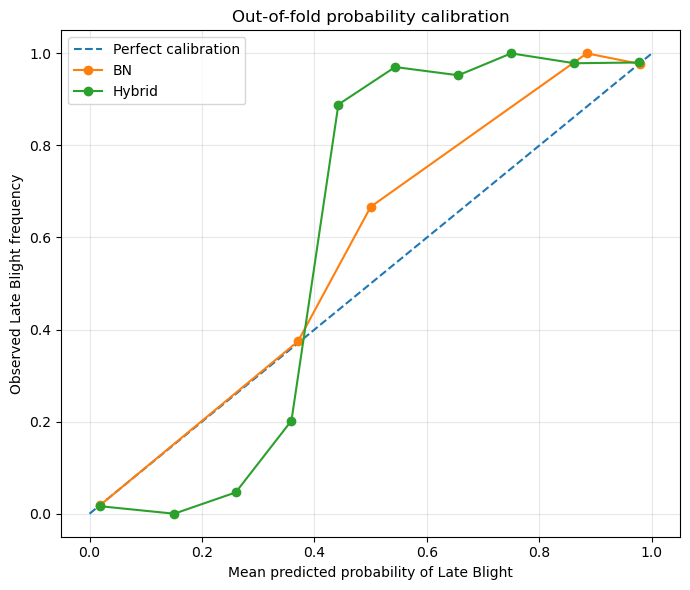


Entropy and confidence by correctness:


,Model,Correct,Observations,Mean_Entropy,Median_Entropy,Mean_Confidence
0,BN,True,3668,0.168221,0.085527,0.934186
1,BN,False,352,0.553795,0.656441,0.693666
2,Hybrid,True,3719,0.225181,0.097780,0.904309
3,Hybrid,False,301,0.573243,0.668691,0.660875



High-confidence prediction errors:


,Model,Threshold,Observations,Errors,Error_Rate
0,BN,0.80,3261,67,0.020546
1,BN,0.90,3242,67,0.020666
2,BN,0.95,3041,62,0.020388
3,Hybrid,0.80,2979,53,0.017791
4,Hybrid,0.90,2825,51,0.018053
5,Hybrid,0.95,2649,44,0.016610



Fold-wise calibration metrics:


,Fold,Model,Log_Loss,Brier,ECE
0,1,BN,0.153206,0.045679,0.018025
1,1,Hybrid,0.164883,0.046582,0.071354
2,2,BN,0.178546,0.050335,0.007225
3,2,Hybrid,0.177762,0.048818,0.062377
4,3,BN,0.232681,0.068317,0.021608
5,3,Hybrid,0.233742,0.067706,0.075627
6,4,BN,0.257041,0.075057,0.010175
7,4,Hybrid,0.258483,0.074630,0.105358
8,5,BN,0.220413,0.063399,0.009114
9,5,Hybrid,0.229214,0.064453,0.061304



Mean and SD across folds:


Log_Loss               Brier                 ECE          
            mean       std      mean       std      mean       std
Model                                                             
BN      0.208377  0.041945  0.060557  0.012292  0.013229  0.006235
Hybrid  0.212817  0.039745  0.060438  0.012221  0.075204  0.017902


Experiment U2 completed.


In [22]:

# ============================================================
# EXPERIMENT U2
# Posterior calibration and uncertainty quality
# BN-only versus H-v1 hybrid
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    log_loss, brier_score_loss
)

# ------------------------------------------------------------
# 1. Reconstruct paired out-of-fold probabilities
# ------------------------------------------------------------

u2_records = []

skf_u2 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

config_lookup = {
    tuple(config): j
    for j, config in enumerate(CONFIGURATIONS)
}

for fold, (train_idx, test_idx) in enumerate(
    skf_u2.split(df[FEATURES], df[TARGET]),
    start=1
):

    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    thresholds = fit_thresholds(
        train_data, scheme="tertile"
    )

    p_j, cpt, classes, counts = (
        estimate_bn_components(train_data, thresholds)
    )

    # Crisp BN posterior
    discrete_test = discretize(
        test_data, thresholds
    )

    states = discrete_test[
        FEATURES
    ].to_numpy(dtype=int)

    config_indices = np.array([
        config_lookup[tuple(row)]
        for row in states
    ])

    bn_posterior = cpt[config_indices]

    # Hybrid posterior
    mf_params = fit_gaussian_mfs(train_data)

    W = fuzzy_configuration_weights(
        test_data, mf_params
    )

    Q, hybrid_posterior, evidence_mass = (
        hybrid_inference(W, p_j, cpt)
    )

    late_index = int(
        np.where(classes == 0)[0][0]
    )

    y_true = test_data[TARGET].to_numpy()
    y_late = (y_true == 0).astype(int)

    p_bn = bn_posterior[:, late_index]
    p_hybrid = hybrid_posterior[:, late_index]

    for i, row_id in enumerate(test_idx):

        u2_records.append({
            "Row_Index": int(row_id),
            "Fold": fold,
            "Actual_Late": int(y_late[i]),
            "P_Late_BN": float(p_bn[i]),
            "P_Late_Hybrid": float(p_hybrid[i]),
            "Evidence_Mass": float(evidence_mass[i])
        })


u2_results = pd.DataFrame(u2_records)

assert len(u2_results) == len(df)
assert u2_results["Row_Index"].is_unique

# ------------------------------------------------------------
# 2. Entropy and correctness
# ------------------------------------------------------------

def binary_entropy(p):
    p = np.asarray(p, dtype=float)
    p_safe = np.clip(p, 1e-300, 1 - 1e-15)

    return -(
        p_safe * np.log(p_safe) +
        (1 - p_safe) * np.log1p(-p_safe)
    )


for model in ["BN", "Hybrid"]:

    p = u2_results[f"P_Late_{model}"].to_numpy()

    u2_results[f"Entropy_{model}"] = (
        binary_entropy(p)
    )

    u2_results[f"Pred_{model}"] = (
        p > 0.5
    ).astype(int)

    u2_results[f"Correct_{model}"] = (
        u2_results[f"Pred_{model}"] ==
        u2_results["Actual_Late"]
    )

    u2_results[f"Confidence_{model}"] = (
        np.maximum(p, 1 - p)
    )


# ------------------------------------------------------------
# 3. Probability-sensitive performance
# ------------------------------------------------------------

performance = []

y = u2_results["Actual_Late"].to_numpy()

for model in ["BN", "Hybrid"]:

    p = u2_results[f"P_Late_{model}"].to_numpy()
    pred = u2_results[f"Pred_{model}"].to_numpy()

    performance.append({
        "Model": model,
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y, p),
        "Log_Loss": log_loss(
            y, p, labels=[0, 1]
        ),
        "Brier": brier_score_loss(y, p),
        "Mean_Entropy": float(
            u2_results[f"Entropy_{model}"].mean()
        )
    })

print("EXPERIMENT U2: POSTERIOR CALIBRATION")
print("=" * 65)

print("\nPooled out-of-fold probability performance:")
display(
    pd.DataFrame(performance).round(6)
)


# ------------------------------------------------------------
# 4. Reliability diagram and expected calibration error
# ------------------------------------------------------------

N_BINS = 10

def calibration_table(y_true, probabilities, n_bins=10):

    edges = np.linspace(0, 1, n_bins + 1)

    bin_ids = np.digitize(
        probabilities,
        edges[1:-1],
        right=False
    )

    rows = []

    for b in range(n_bins):

        mask = bin_ids == b
        n = int(mask.sum())

        if n == 0:
            continue

        rows.append({
            "Bin": b + 1,
            "Count": n,
            "Mean_Predicted": float(
                probabilities[mask].mean()
            ),
            "Observed_Frequency": float(
                y_true[mask].mean()
            )
        })

    return pd.DataFrame(rows)


calibration_results = {}
ece_results = {}

for model in ["BN", "Hybrid"]:

    p = u2_results[
        f"P_Late_{model}"
    ].to_numpy()

    cal = calibration_table(y, p, N_BINS)

    calibration_results[model] = cal

    ece = np.sum(
        (cal["Count"] / len(y)) *
        np.abs(
            cal["Observed_Frequency"] -
            cal["Mean_Predicted"]
        )
    )

    ece_results[model] = float(ece)


print("\nExpected calibration error (10 bins):")

display(
    pd.DataFrame({
        "Model": list(ece_results.keys()),
        "ECE": list(ece_results.values())
    }).round(6)
)

# Reliability plot
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

for model in ["BN", "Hybrid"]:

    cal = calibration_results[model]

    plt.plot(
        cal["Mean_Predicted"],
        cal["Observed_Frequency"],
        marker="o",
        label=model
    )

plt.xlabel("Mean predicted probability of Late Blight")
plt.ylabel("Observed Late Blight frequency")
plt.title("Out-of-fold probability calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Entropy by correctness
# ------------------------------------------------------------

entropy_records = []

for model in ["BN", "Hybrid"]:

    for correct in [True, False]:

        subset = u2_results[
            u2_results[f"Correct_{model}"] == correct
        ]

        entropy_records.append({
            "Model": model,
            "Correct": correct,
            "Observations": len(subset),
            "Mean_Entropy": subset[
                f"Entropy_{model}"
            ].mean(),
            "Median_Entropy": subset[
                f"Entropy_{model}"
            ].median(),
            "Mean_Confidence": subset[
                f"Confidence_{model}"
            ].mean()
        })


print("\nEntropy and confidence by correctness:")

display(
    pd.DataFrame(entropy_records).round(6)
)


# ------------------------------------------------------------
# 6. High-confidence errors
# ------------------------------------------------------------

high_confidence_records = []

for model in ["BN", "Hybrid"]:

    confidence = u2_results[
        f"Confidence_{model}"
    ]

    correct = u2_results[
        f"Correct_{model}"
    ]

    for threshold in [0.80, 0.90, 0.95]:

        mask = confidence >= threshold

        high_confidence_records.append({
            "Model": model,
            "Threshold": threshold,
            "Observations": int(mask.sum()),
            "Errors": int(
                (~correct[mask]).sum()
            ),
            "Error_Rate": (
                float((~correct[mask]).mean())
                if mask.sum() > 0 else np.nan
            )
        })


print("\nHigh-confidence prediction errors:")

display(
    pd.DataFrame(
        high_confidence_records
    ).round(6)
)


# ------------------------------------------------------------
# 7. Calibration by validation fold
# ------------------------------------------------------------

fold_records = []

for fold, subset in u2_results.groupby("Fold"):

    y_fold = subset["Actual_Late"].to_numpy()

    for model in ["BN", "Hybrid"]:

        p_fold = subset[
            f"P_Late_{model}"
        ].to_numpy()

        cal = calibration_table(
            y_fold, p_fold, N_BINS
        )

        ece = np.sum(
            (cal["Count"] / len(subset)) *
            np.abs(
                cal["Observed_Frequency"] -
                cal["Mean_Predicted"]
            )
        )

        fold_records.append({
            "Fold": fold,
            "Model": model,
            "Log_Loss": log_loss(
                y_fold, p_fold, labels=[0, 1]
            ),
            "Brier": brier_score_loss(
                y_fold, p_fold
            ),
            "ECE": ece
        })


u2_fold_results = pd.DataFrame(fold_records)

print("\nFold-wise calibration metrics:")
display(u2_fold_results.round(6))

print("\nMean and SD across folds:")

display(
    u2_fold_results.groupby("Model")[
        ["Log_Loss", "Brier", "ECE"]
    ].agg(["mean", "std"]).round(6)
)

print("\nExperiment U2 completed.")


In [23]:

# ============================================================
# CELL 21 — PREDICTION CONSISTENCY AUDIT AND CORRECTION
# ============================================================
# Original disease coding: 0 = Late, 1 = Early
# Tie rule: use the majority disease class in the training fold.
# This cell does NOT refit any BN or hybrid probabilities.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

# 1. Check required saved results
required = ["df", "TARGET", "final_bn",
            "h4_predictions", "u1_results", "u2_results"]

missing = [name for name in required if name not in globals()]
assert not missing, f"Missing notebook objects: {missing}"

# 2. Reconstruct training-fold majority classes
skf_audit = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

fold_majority = {}
fold_test_indices = {}

for fold, (train_idx, test_idx) in enumerate(
    skf_audit.split(df, df[TARGET]), start=1
):
    majority = int(
        df.iloc[train_idx][TARGET].mode().iloc[0]
    )
    fold_majority[fold] = majority
    fold_test_indices[fold] = set(test_idx)

print("Training-fold majority classes:")
print(fold_majority)

# Determine whether saved fold labels are 0-based or 1-based
saved_folds = set(u2_results["Fold"].unique())
if saved_folds == set(range(5)):
    fold_offset = 1
elif saved_folds == set(range(1, 6)):
    fold_offset = 0
else:
    raise ValueError(
        f"Unexpected saved fold labels: {saved_folds}"
    )

# Verify that fold membership matches the original CV
for fold, indices in fold_test_indices.items():
    saved_fold = fold - fold_offset
    actual_indices = set(
        u2_results.loc[
            u2_results["Fold"] == saved_fold, "Row_Index"
        ]
    )
    assert actual_indices == indices, (
        f"Fold membership mismatch in fold {fold}"
    )

# 3. Build an aligned out-of-fold audit table
audit = u2_results[
    ["Row_Index", "Fold", "Actual_Late",
     "P_Late_BN", "P_Late_Hybrid"]
].copy()

audit["Actual"] = 1 - audit["Actual_Late"]

audit["Majority_Class"] = audit["Fold"].map(
    lambda f: fold_majority[int(f) + fold_offset]
)

def predict_with_ties(p_late, majority):
    if np.isclose(p_late, 0.5, rtol=0, atol=1e-12):
        return int(majority)
    return 0 if p_late > 0.5 else 1

audit["BN_Pred_Corrected"] = [
    predict_with_ties(p, m)
    for p, m in zip(
        audit["P_Late_BN"], audit["Majority_Class"]
    )
]

# Hybrid uses the same tie rule for consistency
audit["Hybrid_Pred_Corrected"] = [
    predict_with_ties(p, m)
    for p, m in zip(
        audit["P_Late_Hybrid"], audit["Majority_Class"]
    )
]

audit["BN_Tie"] = np.isclose(
    audit["P_Late_BN"], 0.5, rtol=0, atol=1e-12
)
audit["Hybrid_Tie"] = np.isclose(
    audit["P_Late_Hybrid"], 0.5, rtol=0, atol=1e-12
)

# 4. Compare against original H4 and U1 predictions
h4_old = h4_predictions[
    ["Row_Index", "Actual", "BN_Pred", "Hybrid_Pred"]
].rename(columns={
    "Actual": "H4_Actual",
    "BN_Pred": "H4_BN_Pred",
    "Hybrid_Pred": "H4_Hybrid_Pred"
})

u1_old = u1_results[
    ["Row_Index", "Actual", "BN_Pred", "Hybrid_Pred"]
].rename(columns={
    "Actual": "U1_Actual",
    "BN_Pred": "U1_BN_Pred",
    "Hybrid_Pred": "U1_Hybrid_Pred"
})

audit = audit.merge(
    h4_old, on="Row_Index", how="inner",
    validate="one_to_one"
).merge(
    u1_old, on="Row_Index", how="inner",
    validate="one_to_one"
)

assert len(audit) == len(df)
assert (audit["Actual"] == audit["H4_Actual"]).all()
assert (audit["Actual"] == audit["U1_Actual"]).all()

print("\n=== TIE AND PREDICTION AUDIT ===")
print("BN posterior ties:", int(audit["BN_Tie"].sum()))
print("Hybrid posterior ties:",
      int(audit["Hybrid_Tie"].sum()))

for source in ["H4", "U1"]:
    for model in ["BN", "Hybrid"]:
        old_col = f"{source}_{model}_Pred"
        new_col = f"{model}_Pred_Corrected"
        changed = int(
            (audit[old_col] != audit[new_col]).sum()
        )
        print(f"{source} {model} predictions changed: {changed}")

# 5. Compare corrected BN against original BN evaluation
# final_bn stores predictions in fold-concatenated order,
# so reconstruct row indices in that same order.
ordered_test_indices = []
for _, test_idx in skf_audit.split(df, df[TARGET]):
    ordered_test_indices.extend(test_idx.tolist())

original_bn = pd.DataFrame({
    "Row_Index": ordered_test_indices,
    "Original_BN_Pred": final_bn["y_pred"],
    "Original_Actual": final_bn["y_true"]
})

audit = audit.merge(
    original_bn, on="Row_Index",
    how="inner", validate="one_to_one"
)

assert (audit["Actual"] == audit["Original_Actual"]).all()

bn_mismatches = int((
    audit["BN_Pred_Corrected"] !=
    audit["Original_BN_Pred"]
).sum())

print("\nOriginal BN vs corrected BN mismatches:",
      bn_mismatches)

# 6. Corrected paired performance
audit["BN_Correct"] = (
    audit["BN_Pred_Corrected"] == audit["Actual"]
)
audit["Hybrid_Correct"] = (
    audit["Hybrid_Pred_Corrected"] == audit["Actual"]
)

both_correct = int(
    (audit["BN_Correct"] & audit["Hybrid_Correct"]).sum()
)
both_wrong = int(
    (~audit["BN_Correct"] & ~audit["Hybrid_Correct"]).sum()
)
fixes = int(
    (~audit["BN_Correct"] & audit["Hybrid_Correct"]).sum()
)
breaks = int(
    (audit["BN_Correct"] & ~audit["Hybrid_Correct"]).sum()
)

bn_accuracy = accuracy_score(
    audit["Actual"], audit["BN_Pred_Corrected"]
)
hybrid_accuracy = accuracy_score(
    audit["Actual"], audit["Hybrid_Pred_Corrected"]
)

print("\n=== CORRECTED PAIRED RESULTS ===")
print(f"BN accuracy:       {bn_accuracy:.6f}")
print(f"Hybrid accuracy:   {hybrid_accuracy:.6f}")
print(f"Accuracy gain:     {hybrid_accuracy-bn_accuracy:.6f}")
print(f"Both correct:      {both_correct}")
print(f"Both incorrect:    {both_wrong}")
print(f"Hybrid fixes BN:   {fixes}")
print(f"Hybrid introduces: {breaks}")
print(f"Net corrections:   {fixes-breaks}")

# Exact McNemar test
paired_table = [
    [both_correct, breaks],
    [fixes, both_wrong]
]

mc = mcnemar(paired_table, exact=True)

print(f"McNemar statistic: {mc.statistic:.0f}")
print(f"McNemar p-value:   {mc.pvalue:.12g}")

# 7. Corrected confusion matrices
for model in ["BN", "Hybrid"]:
    cm = confusion_matrix(
        audit["Actual"],
        audit[f"{model}_Pred_Corrected"],
        labels=[0, 1]
    )
    print(f"\n{model} confusion matrix:")
    print("Rows/columns: Late (0), Early (1)")
    print(cm)

# 8. Update prediction-dependent columns for U1 and U2
corrected = audit.set_index("Row_Index")

for frame in [h4_predictions, u1_results]:
    for model in ["BN", "Hybrid"]:
        frame[f"{model}_Pred"] = frame["Row_Index"].map(
            corrected[f"{model}_Pred_Corrected"]
        )
        frame[f"{model}_Correct"] = (
            frame[f"{model}_Pred"] == frame["Actual"]
        )

for model in ["BN", "Hybrid"]:
    u2_results[f"Pred_{model}"] = (
        1 - u2_results["Row_Index"].map(
            corrected[f"{model}_Pred_Corrected"]
        )
    ).astype(int)

    u2_results[f"Correct_{model}"] = (
        u2_results[f"Pred_{model}"] ==
        u2_results["Actual_Late"]
    )

# 9. Final assertions
assert bn_mismatches == 0, (
    "Corrected BN still differs from original BN. "
    "Investigate before freezing results."
)

assert both_correct + both_wrong + fixes + breaks == len(df)

assert fixes - breaks == (
    int(audit["Hybrid_Correct"].sum()) -
    int(audit["BN_Correct"].sum())
)

print("\nAUDIT PASSED: corrected predictions are consistent.")
print("Posterior probabilities and entropy values unchanged.")


Training-fold majority classes:
{1: 1, 2: 1, 3: 1, 4: 1, 5: 1}

=== TIE AND PREDICTION AUDIT ===
BN posterior ties: 3
Hybrid posterior ties: 0
H4 BN predictions changed: 3
H4 Hybrid predictions changed: 0
U1 BN predictions changed: 3
U1 Hybrid predictions changed: 0

Original BN vs corrected BN mismatches: 0

=== CORRECTED PAIRED RESULTS ===
BN accuracy:       0.912438
Hybrid accuracy:   0.925124
Accuracy gain:     0.012687
Both correct:      3659
Both incorrect:    292
Hybrid fixes BN:   60
Hybrid introduces: 9
Net corrections:   51
McNemar statistic: 9
McNemar p-value:   2.24444964513e-10

BN confusion matrix:
Rows/columns: Late (0), Early (1)
[[1640  314]
 [  38 2028]]

Hybrid confusion matrix:
Rows/columns: Late (0), Early (1)
[[1689  265]
 [  36 2030]]

AUDIT PASSED: corrected predictions are consistent.
Posterior probabilities and entropy values unchanged.


In [24]:

# ============================================================
# CELL 22 — REPEATED WEATHER PATTERNS AND CV ROBUSTNESS
# Diagnostic audit only: no model refitting
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

assert all(x in globals() for x in [
    "df", "FEATURES", "TARGET", "audit"
])

# 1. Construct exact weather-pattern identifiers
# No rounding: identical means exactly identical recorded values.
weather = df[FEATURES].reset_index(drop=True).copy()
labels = df[TARGET].reset_index(drop=True)

pattern_keys = pd.MultiIndex.from_frame(weather)
pattern_counts = weather.value_counts(dropna=False)

print("=== DATASET PATTERN SUMMARY ===")
print("Total observations:", len(weather))
print("Unique weather patterns:", len(pattern_counts))
print("Duplicate rows beyond first occurrence:",
      len(weather) - len(pattern_counts))
print("Observations belonging to repeated patterns:",
      int(pattern_counts[pattern_counts > 1].sum()))
print("Largest pattern frequency:", int(pattern_counts.max()))

# 2. Identify weather patterns associated with both diseases
pattern_label_counts = (
    pd.concat([weather, labels.rename(TARGET)], axis=1)
    .groupby(FEATURES, dropna=False)[TARGET]
    .nunique()
)

conflicting_patterns = pattern_label_counts[
    pattern_label_counts > 1
]

print("Patterns with conflicting disease labels:",
      len(conflicting_patterns))

# 3. Reconstruct the original five-fold CV
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

records = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(weather, labels), start=1
):
    train_keys = set(pattern_keys[train_idx].tolist())
    test_keys = pattern_keys[test_idx].tolist()

    seen = np.array(
        [key in train_keys for key in test_keys],
        dtype=bool
    )

    for idx, is_seen in zip(test_idx, seen):
        records.append({
            "Row_Index": int(idx),
            "Fold": fold,
            "Seen_In_Training": bool(is_seen)
        })

pattern_audit = pd.DataFrame(records)

assert len(pattern_audit) == len(df)
assert pattern_audit["Row_Index"].is_unique

print("\n=== TRAIN–TEST PATTERN OVERLAP ===")
print(pd.crosstab(
    pattern_audit["Fold"],
    pattern_audit["Seen_In_Training"],
    margins=True
))

# 4. Join with corrected out-of-fold predictions
evaluation = pattern_audit.merge(
    audit[[
        "Row_Index", "Actual",
        "BN_Pred_Corrected",
        "Hybrid_Pred_Corrected"
    ]],
    on="Row_Index",
    how="inner",
    validate="one_to_one"
)

assert len(evaluation) == len(df)

# 5. Compare predictive accuracy by pattern novelty
rows = []

for model, pred_col in [
    ("BN-only", "BN_Pred_Corrected"),
    ("Hybrid", "Hybrid_Pred_Corrected")
]:
    for seen_status, group in evaluation.groupby(
        "Seen_In_Training"
    ):
        rows.append({
            "Model": model,
            "Pattern_Group": (
                "Previously seen"
                if seen_status else "Unseen"
            ),
            "N": len(group),
            "Accuracy": accuracy_score(
                group["Actual"], group[pred_col]
            ),
            "Errors": int(
                (group["Actual"] != group[pred_col]).sum()
            )
        })

pattern_performance = pd.DataFrame(rows)

print("\n=== ACCURACY BY WEATHER-PATTERN NOVELTY ===")
print(pattern_performance.to_string(
    index=False,
    float_format=lambda x: f"{x:.6f}"
))

# 6. Inspect whether overlap varies across folds
fold_summary = (
    pattern_audit.groupby("Fold")["Seen_In_Training"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Seen",
        "count": "Test_N",
        "mean": "Seen_Fraction"
    })
)

print("\n=== FOLD-LEVEL OVERLAP ===")
print(fold_summary.to_string(
    float_format=lambda x: f"{x:.4f}"
))

# 7. Final checks
assert evaluation["Actual"].isin([0, 1]).all()
assert evaluation["Row_Index"].nunique() == len(df)

print("\nAUDIT COMPLETE.")
print("No model parameters or predictions were changed.")


=== DATASET PATTERN SUMMARY ===
Total observations: 4020
Unique weather patterns: 2742
Duplicate rows beyond first occurrence: 1278
Observations belonging to repeated patterns: 1773
Largest pattern frequency: 43
Patterns with conflicting disease labels: 28

=== TRAIN–TEST PATTERN OVERLAP ===
Seen_In_Training  False  True   All
Fold                               
1                   481   323   804
2                   474   330   804
3                   489   315   804
4                   485   319   804
5                   471   333   804
All                2400  1620  4020

=== ACCURACY BY WEATHER-PATTERN NOVELTY ===
  Model   Pattern_Group    N  Accuracy  Errors
BN-only          Unseen 2400  0.917083     199
BN-only Previously seen 1620  0.905556     153
 Hybrid          Unseen 2400  0.917083     199
 Hybrid Previously seen 1620  0.937037     102

=== FOLD-LEVEL OVERLAP ===
      Seen  Test_N  Seen_Fraction
Fold                             
1      323     804         0.4017
2      33

In [25]:

# ============================================================
# CELL 23 — GROUPED FIVE-FOLD ROBUSTNESS EXPERIMENT
# BN-only vs Fuzzy-only vs H-v1 Hybrid
#
# Identical (Temperature, Humidity, Visibility) patterns
# cannot occur in both training and test partitions.
#
# Reuses functions from earlier notebook cells.
# No existing results are overwritten.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, log_loss, brier_score_loss,
    roc_auc_score, confusion_matrix
)

# ------------------------------------------------------------
# 1. Verify dependencies
# ------------------------------------------------------------

required_functions = [
    "fit_thresholds",
    "discretize",
    "direct_bn_predict",
    "fit_gaussian_mfs",
    "fuzzy_configuration_weights",
    "estimate_bn_components",
    "hybrid_inference",
    "fit_fuzzy_rules",
    "fuzzy_only_predict"
]

missing = [
    name for name in required_functions
    if name not in globals()
]

assert not missing, f"Missing functions: {missing}"

X = df[FEATURES].reset_index(drop=True)
y = df[TARGET].reset_index(drop=True)

assert set(y.unique()) == {0, 1}
assert not X.isna().any().any()

# Give each exact weather configuration a group ID.
groups = pd.factorize(
    pd.MultiIndex.from_frame(X),
    sort=False
)[0]

print("=== GROUPED CROSS-VALIDATION ===")
print("Observations:", len(y))
print("Unique weather-pattern groups:", len(np.unique(groups)))

# Explicit historical fold IDs are supplied for exact reproduction of
# manuscript Tables 8 and 9. See README for the scikit-learn caveat.
from pathlib import Path
folds_path = Path("grouped_folds_historical.csv")
assert folds_path.is_file(), f"Missing fold assignments: {folds_path}"
folds_df = pd.read_csv(folds_path)
assert len(folds_df) == len(df)
assert set(folds_df.columns) == {"Row_Index", "Fold"}
assert not folds_df["Row_Index"].duplicated().any()
assert set(folds_df["Row_Index"]) == set(range(len(df)))
fold_ids = folds_df.set_index("Row_Index").loc[np.arange(len(df)), "Fold"].to_numpy()
assert set(fold_ids) == set(range(1, 6))

grouped_splits = [
    (np.flatnonzero(fold_ids != fold), np.flatnonzero(fold_ids == fold))
    for fold in range(1, 6)
]
# Confirm exact weather configurations never cross the train/test boundary.
for train_idx, test_idx in grouped_splits:
    assert set(groups[train_idx]).isdisjoint(set(groups[test_idx]))

# Verify that all test partitions are disjoint and exhaustive.
all_test = np.concatenate([
    test_idx for _, test_idx in grouped_splits
])

assert len(all_test) == len(df)
assert len(np.unique(all_test)) == len(df)

# ------------------------------------------------------------
# 2. Metric function
# ------------------------------------------------------------

def grouped_metrics(y_true, y_pred, p_late=None):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Late_Precision": precision_score(
            y_true, y_pred, pos_label=0,
            zero_division=0
        ),
        "Late_Recall": recall_score(
            y_true, y_pred, pos_label=0,
            zero_division=0
        ),
        "Late_F1": f1_score(
            y_true, y_pred, pos_label=0,
            zero_division=0
        )
    }

    if p_late is not None:
        actual_late = (np.asarray(y_true) == 0).astype(int)
        p_late = np.asarray(p_late, dtype=float)

        result["Log_Loss"] = log_loss(
            actual_late,
            np.column_stack([1 - p_late, p_late]),
            labels=[0, 1]
        )

        result["Brier"] = brier_score_loss(
            actual_late, p_late
        )

        result["AUC"] = (
            roc_auc_score(actual_late, p_late)
            if len(np.unique(actual_late)) == 2
            else np.nan
        )

    return result


# ------------------------------------------------------------
# 3. Evaluate three models on identical grouped folds
# ------------------------------------------------------------

grouped_records = []
grouped_predictions = []
grouped_fold_diagnostics = []

for fold, (train_idx, test_idx) in enumerate(
    grouped_splits, start=1
):

    train_data = df.iloc[train_idx].copy()
    test_data = df.iloc[test_idx].copy()

    y_train = train_data[TARGET].to_numpy()
    y_test = test_data[TARGET].to_numpy()

    # Strict group separation
    train_groups = set(groups[train_idx])
    test_groups = set(groups[test_idx])

    assert train_groups.isdisjoint(test_groups)

    # -------------------------
    # A. BN-only
    # -------------------------

    thresholds = fit_thresholds(
        train_data, scheme="tertile"
    )

    train_disc = discretize(
        train_data, thresholds
    )

    test_disc = discretize(
        test_data, thresholds
    )

    bn_pred, bn_p_early, bn_diag = direct_bn_predict(
        train_disc,
        y_train,
        test_disc,
        estimator="bdeu",
        ess=5
    )

    bn_p_late = 1 - bn_p_early

    # -------------------------
    # B. Fuzzy-only
    # -------------------------

    mf_params = fit_gaussian_mfs(train_data)

    (
        rule_consequents,
        rule_confidence,
        rule_supports,
        fuzzy_classes
    ) = fit_fuzzy_rules(train_data, mf_params)

    fuzzy_pred, fuzzy_support = fuzzy_only_predict(
        test_data,
        mf_params,
        rule_consequents,
        rule_confidence,
        fuzzy_classes
    )

    # Fuzzy support is NOT a probability.
    # Therefore no AUC/log-loss/Brier for fuzzy-only.

    # -------------------------
    # C. H-v1 Hybrid
    # -------------------------

    W_test = fuzzy_configuration_weights(
        test_data, mf_params
    )

    p_j, cpt, classes, counts = estimate_bn_components(
        train_data, thresholds
    )

    Q, hybrid_posterior, denominator = hybrid_inference(
        W_test, p_j, cpt
    )

    late_idx = int(np.where(classes == 0)[0][0])
    hybrid_p_late = hybrid_posterior[:, late_idx]

    # Use training-majority tie handling, as in Cell 21.
    majority_class = int(
        pd.Series(y_train).mode().iloc[0]
    )

    hybrid_pred = np.where(
        np.isclose(
            hybrid_p_late, 0.5,
            rtol=0, atol=1e-12
        ),
        majority_class,
        np.where(hybrid_p_late > 0.5, 0, 1)
    ).astype(int)

    # Mathematical checks
    assert np.allclose(
        hybrid_posterior.sum(axis=1), 1.0
    )
    assert np.all(np.isfinite(hybrid_posterior))
    assert np.all(denominator > 0)

    # -------------------------
    # D. Store metrics
    # -------------------------

    for model, prediction, probability in [
        ("BN-only", bn_pred, bn_p_late),
        ("Fuzzy-only", fuzzy_pred, None),
        ("Hybrid H-v1", hybrid_pred, hybrid_p_late)
    ]:

        grouped_records.append({
            "Fold": fold,
            "Model": model,
            "Train_N": len(train_idx),
            "Test_N": len(test_idx),
            **grouped_metrics(
                y_test, prediction, probability
            )
        })

    grouped_fold_diagnostics.append({
        "Fold": fold,
        "Train_N": len(train_idx),
        "Test_N": len(test_idx),
        "Train_Late_Pct": np.mean(y_train == 0) * 100,
        "Test_Late_Pct": np.mean(y_test == 0) * 100,
        "Group_Overlap": len(
            train_groups.intersection(test_groups)
        ),
        "Empty_BN_Configurations": int(
            (counts.sum(axis=1) == 0).sum()
        ),
        "BN_Ties": int(bn_diag["ties"]),
        "Min_Evidence_Mass": float(denominator.min())
    })

    for i, row_id in enumerate(test_idx):
        grouped_predictions.append({
            "Row_Index": int(row_id),
            "Fold": fold,
            "Actual": int(y_test[i]),
            "BN_Pred": int(bn_pred[i]),
            "Fuzzy_Pred": int(fuzzy_pred[i]),
            "Hybrid_Pred": int(hybrid_pred[i]),
            "BN_P_Late": float(bn_p_late[i]),
            "Hybrid_P_Late": float(hybrid_p_late[i])
        })

    print(
        f"Fold {fold} complete | "
        f"Test N={len(test_idx)} | "
        f"BN={accuracy_score(y_test, bn_pred):.4f} | "
        f"Fuzzy={accuracy_score(y_test, fuzzy_pred):.4f} | "
        f"Hybrid={accuracy_score(y_test, hybrid_pred):.4f}"
    )

# ------------------------------------------------------------
# 4. Consolidate results
# ------------------------------------------------------------

grouped_results = pd.DataFrame(grouped_records)
grouped_predictions = pd.DataFrame(grouped_predictions)
grouped_diagnostics = pd.DataFrame(
    grouped_fold_diagnostics
)

assert len(grouped_predictions) == len(df)
assert grouped_predictions["Row_Index"].is_unique
assert (grouped_diagnostics["Group_Overlap"] == 0).all()

metrics_to_summarize = [
    "Accuracy",
    "Macro_F1",
    "Late_Precision",
    "Late_Recall",
    "Late_F1",
    "AUC",
    "Log_Loss",
    "Brier"
]

grouped_summary = (
    grouped_results
    .groupby("Model")[metrics_to_summarize]
    .agg(["mean", "std"])
)

print("\n=== FOLD DIAGNOSTICS ===")
display(grouped_diagnostics.round(6))

print("\n=== FOLD-WISE PERFORMANCE ===")
display(grouped_results.round(6))

print("\n=== GROUPED CV: MEAN AND SD ===")
display(grouped_summary.round(6))

# ------------------------------------------------------------
# 5. Pooled accuracy and confusion matrices
# ------------------------------------------------------------

print("\n=== POOLED GROUPED-CV RESULTS ===")

for model, pred_col in [
    ("BN-only", "BN_Pred"),
    ("Fuzzy-only", "Fuzzy_Pred"),
    ("Hybrid H-v1", "Hybrid_Pred")
]:

    acc = accuracy_score(
        grouped_predictions["Actual"],
        grouped_predictions[pred_col]
    )

    cm = confusion_matrix(
        grouped_predictions["Actual"],
        grouped_predictions[pred_col],
        labels=[0, 1]
    )

    print(f"\n{model}: pooled accuracy = {acc:.6f}")
    print("Rows/columns: Late (0), Early (1)")
    print(cm)

# ------------------------------------------------------------
# 6. Paired BN–Hybrid comparison
# ------------------------------------------------------------

bn_correct = (
    grouped_predictions["BN_Pred"] ==
    grouped_predictions["Actual"]
)

hybrid_correct = (
    grouped_predictions["Hybrid_Pred"] ==
    grouped_predictions["Actual"]
)

grouped_fixes = int(
    (~bn_correct & hybrid_correct).sum()
)

grouped_breaks = int(
    (bn_correct & ~hybrid_correct).sum()
)

print("\n=== GROUPED BN–HYBRID COMPARISON ===")
print("Hybrid fixes BN errors:", grouped_fixes)
print("Hybrid introduces errors:", grouped_breaks)
print("Net additional correct:", grouped_fixes - grouped_breaks)

print("\nFINAL GROUPED VALIDATION COMPLETE.")
print("Original stratified-CV results remain unchanged.")


=== GROUPED CROSS-VALIDATION ===
Observations: 4020
Unique weather-pattern groups: 2742
Fold 1 complete | Test N=788 | BN=0.9378 | Fuzzy=0.9492 | Hybrid=0.9391
Fold 2 complete | Test N=767 | BN=0.9022 | Fuzzy=0.9413 | Hybrid=0.9270
Fold 3 complete | Test N=830 | BN=0.8831 | Fuzzy=0.9410 | Hybrid=0.9253
Fold 4 complete | Test N=781 | BN=0.9001 | Fuzzy=0.9385 | Hybrid=0.9245
Fold 5 complete | Test N=854 | BN=0.9368 | Fuzzy=0.9485 | Hybrid=0.9415

=== FOLD DIAGNOSTICS ===


,Fold,Train_N,Test_N,Train_Late_Pct,Test_Late_Pct,Group_Overlap,Empty_BN_Configurations,BN_Ties,Min_Evidence_Mass
0,1,3232,788,47.370050,53.680203,0,8,1,0.000000
1,2,3253,767,49.400553,45.241199,0,8,1,0.000000
2,3,3190,830,47.053292,54.578313,0,7,0,0.000000
3,4,3239,781,50.231553,41.869398,0,8,2,0.000000
4,5,3166,854,48.957675,47.306792,0,7,0,0.000022



=== FOLD-WISE PERFORMANCE ===


,Fold,Model,Train_N,Test_N,Accuracy,Macro_F1,Late_Precision,Late_Recall,Late_F1,Log_Loss,Brier,AUC
0,1,BN-only,3232,788,0.937817,0.937680,0.965174,0.917258,0.940606,0.181338,0.049062,0.963678
1,1,Fuzzy-only,3232,788,0.949239,0.949065,0.965937,0.938534,0.952038,NaN,NaN,NaN
2,1,Hybrid H-v1,3232,788,0.939086,0.938959,0.967581,0.917258,0.941748,0.166994,0.044844,0.978345
3,2,BN-only,3253,767,0.902216,0.899042,0.978873,0.801153,0.881141,0.209712,0.062165,0.966605
4,2,Fuzzy-only,3253,767,0.941330,0.940274,0.974843,0.893372,0.932331,NaN,NaN,NaN
5,2,Hybrid H-v1,3253,767,0.926988,0.925187,0.983389,0.853026,0.913580,0.208299,0.058811,0.979004
6,3,BN-only,3190,830,0.883133,0.883128,0.978495,0.803532,0.882424,0.237887,0.074156,0.960467
7,3,Fuzzy-only,3190,830,0.940964,0.940790,0.978673,0.911700,0.944000,NaN,NaN,NaN
8,3,Hybrid H-v1,3190,830,0.925301,0.925190,0.977995,0.883002,0.928074,0.224554,0.064556,0.982378
9,4,BN-only,3239,781,0.900128,0.893342,0.984436,0.773700,0.866438,0.230028,0.069548,0.954853



=== GROUPED CV: MEAN AND SD ===


Accuracy            Macro_F1           Late_Precision           Late_Recall             Late_F1                 AUC  \
                 mean       std      mean       std           mean       std        mean       std      mean       std      mean   
Model                                                                                                                              
BN-only      0.912012  0.024238  0.909856  0.025330       0.978081  0.007687    0.835366  0.060812  0.900023  0.032826  0.962570   
Fuzzy-only   0.943710  0.004828  0.942758  0.005686       0.977360  0.007578    0.903493  0.026785  0.938728  0.011767       NaN   
Hybrid H-v1  0.931457  0.008139  0.930087  0.009227       0.980325  0.008126    0.874624  0.034388  0.924059  0.016233  0.980016   

                       Log_Loss               Brier            
                  std      mean       std      mean       std  
Model                                                          
BN-only      0.005083  0.211605  0.022952  0.062305  0.010012  
Fuzzy-only        NaN       NaN       NaN       NaN       NaN  
Hybrid H-v1  0.001740  0.208060  0.024341  0.058887  0.008216


=== POOLED GROUPED-CV RESULTS ===

BN-only: pooled accuracy = 0.912189
Rows/columns: Late (0), Early (1)
[[1639  315]
 [  38 2028]]

Fuzzy-only: pooled accuracy = 0.943781
Rows/columns: Late (0), Early (1)
[[1770  184]
 [  42 2024]]

Hybrid H-v1: pooled accuracy = 0.931592
Rows/columns: Late (0), Early (1)
[[1715  239]
 [  36 2030]]

=== GROUPED BN–HYBRID COMPARISON ===
Hybrid fixes BN errors: 87
Hybrid introduces errors: 9
Net additional correct: 78

FINAL GROUPED VALIDATION COMPLETE.
Original stratified-CV results remain unchanged.
